In [1]:
import os
import time as tt
import math
import re
from collections import Counter
import glob

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import cmcrameri.cm as cmc

import roboarmanalysis as ra
import trackpy as tp

from scipy.stats import circmean, skew
from scipy.signal import correlate
from scipy.optimize import curve_fit
from statsmodels import robust

import numpy as np
from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import argrelextrema
from scipy.ndimage import gaussian_filter1d




def compute_phase_energy_landscapes(
    m,
    phases,
    bins=72,
    phi_range=(-np.pi, np.pi),
    phi_col='phi',
    time_col='averagetime'
):
    """
    For each phase in `phases`, slice m.locs by its time window,
    compute per-particle energy landscapes U(phi),
    and save on `m`:
      - m.energy_centers:  1D array of length=bins
      - m.energy_landscapes: dict[phase] -> dict[pid] -> E(phi) array
      - m.barriers:         dict[phase] -> dict[pid] -> barrier height
    """
    edges   = np.linspace(phi_range[0], phi_range[1], bins+1)
    centers = 0.5*(edges[:-1] + edges[1:])
    m.energy_centers    = centers
    m.energy_landscapes = {}
    m.barriers          = {}

    for phase in phases:
        t0, t1 = m.protocol[phase][:2]
        df = m.locs.query(f"@t0 <= {time_col} <= @t1").copy()

        eland = {}
        bars  = {}
        for pid in sorted(df['group'].unique()):
            raw = df.loc[df['group']==pid, phi_col].dropna().to_numpy()
            if raw.size < 2:
                eland[pid] = np.full(bins, np.nan)
                bars[pid]  = np.nan
                continue
            
            hist, _ = np.histogram(raw, bins=edges, density=True)
            p = hist / np.sum(hist)
            E = np.where(p>0, -np.log(p), np.nan)
            E0 = E - np.nanmin(E)
            
            eland[pid] = E0
            bars[pid]  = np.nanmax(E0)

            #         centers, E = compute_energy(raw, bins=bins)
            # # shift minimum to zero
            # E0 = E - np.nanmin(E)

            # eland[pid] = E0
            # bars[pid]  = np.nanmax(E0)


        m.energy_landscapes[phase] = eland
        m.barriers[phase] = bars

    return m.energy_centers, m.energy_landscapes, m.barriers


# Analysis: clusters + energy landscapes
def analyze_particle_clusters(
    m,
    phase,
    particles=None,
    phi_col='phi',
    time_col='averagetime',
    n_bins=72,
    phi_range=(-np.pi, np.pi),
    std_frac=0.5,
    barrier_thresh=4.0,
    well_sigma=2,
    well_depth_frac=0.4
):
    """
    Compute circular stats and energy landscapes for each particle,
    then cluster into five categories stored on `m`:
      - m.particle_clusters: dict[label] -> list of pids
      - m.energy_centers:  1D array of bin centers
      - m.energy_landscapes: dict[pid] -> energy array
    """
    if particles is None:
        particles = sorted(m.locs['group'].unique())
    if not getattr(m, '_has_protocol', False):
        raise RuntimeError("Load protocol and set m._has_protocol=True")

    # Slice by time window
    t0, t1 = m.protocol[phase][:2]
    df = m.locs.query(f"group in @particles and @t0 <= {time_col} <= @t1").copy()

    # Bin setup
    bins_full = np.linspace(phi_range[0], phi_range[1], n_bins+1)
    centers = 0.5 * (bins_full[:-1] + bins_full[1:])

    stds, skews, kurts, barriers, energies = {}, {}, {}, {}, {}
    for pid in particles:
        raw = df.loc[df['group'] == pid, phi_col].dropna().to_numpy()
        if raw.size == 0:
            stds[pid] = skews[pid] = kurts[pid] = barriers[pid] = np.nan
            energies[pid] = np.full(n_bins, np.nan)
            continue

        mu = circmean(raw, low=-np.pi, high=np.pi)
        phi_rel = ((raw - mu + np.pi) % (2 * np.pi)) - np.pi

        stds[pid] = circstd(phi_rel, low=-np.pi, high=np.pi)
        skews[pid] = skew(phi_rel)
        kurts[pid] = kurtosis(phi_rel, fisher=True, bias=False)

        _, E = compute_energy(phi_rel, bins_full)
        E0 = E - np.nanmin(E)
        energies[pid] = E0
        barriers[pid] = np.nanmax(E0)

    # Thresholds
    std_vals = np.array(list(stds.values()))
    std_thr = np.nanpercentile(std_vals, std_frac * 100)

    # Clustering into five groups
    low_std = [p for p in particles if stds[p] <= std_thr]
    high_std = [p for p in particles if stds[p] > std_thr]
    highstd_deep = [p for p in high_std if barriers[p] >= barrier_thresh]
    highstd_rest = [p for p in high_std if barriers[p] < barrier_thresh]
    deep_pos = [p for p in highstd_deep if skews[p] > 0]
    deep_neg = [p for p in highstd_deep if skews[p] < 0]
    lowstd_pos = [p for p in low_std if skews[p] > 0]
    lowstd_neg = [p for p in low_std if skews[p] < 0]

    groups = [
        ("deep, skew>0",    lowstd_pos),
        ("deep, skew<0",    lowstd_neg),
        ("medium skew>0",   deep_pos),
        ("medium, skew<0",  deep_neg),
        ("others",          highstd_rest)
    ]

    # Store lookup + landscapes on model
    m.particle_clusters  = {label: members for label, members in groups}
    m.energy_centers     = centers
    m.energy_landscapes  = energies

def build_protocol(
    m,
    voltages,
    positions,
    diff_start=0.0,
    diff_length=20.0,
    segment_time=0.0
):
    """
    Construct m.protocol dict with entries
      phase_key: (start_time, end_time, start_frame)
    so that calc_trajectories can do range(start_frame, …).

    Also sets on m:
      - m.phases: full ordered list of keys
      - m.all_phases: list excluding 'diff'
      - m.voltage_phases: dict[V] -> list of its position‐phase keys
    Returns m.phases.
    """
    protocol = {}
    # diffusion window
    t0 = diff_start
    t1 = diff_start + diff_length
    f0 = int(t0)
    protocol['diff'] = (t0, t1, f0)
    t = t1

    # fixed-angle windows and per-voltage blocks
    voltage_phases = {}
    for V in voltages:
        voltage_phases[V] = []
        block_start_t = t
        block_start_f = int(block_start_t)

        for pos in positions:
            phase = f"{V}V-{pos}"
            start_t = t
            end_t = t + segment_time
            start_f = int(start_t)

            protocol[phase] = (start_t, end_t, start_f)
            voltage_phases[V].append(phase)

            t = end_t

        # full-voltage block
        full_key = f"{V}V"
        protocol[full_key] = (block_start_t, t, block_start_f)

    # all-time window
    all_start_f = int(diff_start)
    protocol['all'] = (diff_start, t, all_start_f)

    # assign to model
    m.protocol = protocol
    m.phases = list(protocol.keys())
    m.all_phases = m.phases[1:]           # drop 'diff'
    m.voltage_phases = voltage_phases

    return m.phases


def multiple_formatter(denominator=2, number=np.pi, latex='\pi'):
    def gcd(a, b):
        while b:
            a, b = b, a%b
        return a
    def _multiple_formatter(x, pos):
        den = denominator
        num = int(np.rint(den*x/number))
        com = gcd(num,den)
        (num,den) = (int(num/com),int(den/com))
        if den==1:
            if num==0:
                return r'$0$'
            if num==1:
                return r'$%s$'%latex
            elif num==-1:
                return r'$-%s$'%latex
            else:
                return r'$%s%s$'%(num,latex)
        else:
            if num==1:
                return r'$\frac{%s}{%s}$'%(latex,den)
            elif num==-1:
                return r'$\frac{-%s}{%s}$'%(latex,den)
            else:
                return r'$\frac{%s%s}{%s}$'%(num,latex,den)
    return _multiple_formatter

# === Lean reorder-by-variant (A..F) ===========================================
import re

# Precedence matters (most specific first)
_RULES = [
    (re.compile(r'[/\\]ratchet2_eds([/\\]|_|$)', re.I), 'F'),
    (re.compile(r'[/\\]ratchet2_e([/\\]|_|$)',   re.I), 'C'),
    (re.compile(r'[/\\]ratchet2_8ds([/\\]|_|$)', re.I), 'E'),
    (re.compile(r'[/\\]ratchet2_8([/\\]|_|$)',   re.I), 'D'),
    (re.compile(r'[/\\]ratchet2_0([/\\]|_|$)',   re.I), 'B'),
    (re.compile(r'[/\\]ratchet1_0([/\\]|_|$)',   re.I), 'A'),
]
_ORDER = {'A':0,'B':1,'C':2,'D':3,'E':4,'F':5}

def _path_of(m):
    for a in ("path","filepath","file","filename","source","source_file",
              "hdf5_path","hdf5","directory","dirpath"):
        v = getattr(m, a, None)
        if isinstance(v, str) and v: return v
    for a in ("meta","info","attrs","props"):
        d = getattr(m, a, None)
        if isinstance(d, dict):
            for k in ("path","filepath","file","filename","source","source_file",
                      "hdf5_path","hdf5","directory","dirpath"):
                v = d.get(k)
                if isinstance(v, str) and v: return v
    return str(m)

def _variant(path):
    s = path  # regex are case-insensitive and handle / or \
    for rgx, lab in _RULES:
        if rgx.search(s): return lab
    return "Unknown"

def reorder_by_variant(m_list, annotate=True):
    packed = []
    for i, m in enumerate(m_list):
        p = _path_of(m)
        v = _variant(p)
        if annotate:
            for k, val in (("variant", v), ("source_path", p)):
                try: setattr(m, k, val)
                except Exception: pass
        packed.append(( _ORDER.get(v, 1_000_000), i, m))
    packed.sort(key=lambda t: (t[0], t[1]))
    return [m for _,__,m in packed]


trimmed_cmap = lambda name, n, lo=0.2, hi=0.8: \
    plt.colormaps[name](np.linspace(lo, hi, n))
colormap = plt.colormaps.get_cmap('cmc.vik').resampled(14)

%matplotlib inline

In [2]:
dataset_root = r"R:\_06__Umbrella_Sampling\01_Dataset\20260925_L2ss_PAINT"
keywords = ["ROT"]
m_list_original = ra.load_multiple_measurements(dataset_root, keywords=keywords)

allowed_missed_percentage = 30
frame_threshold = (1 - allowed_missed_percentage/100) * (3/0.005)



 >>> y-coordinates are flipped to account for TIRFM geometry (now aligns with micromanager and picasso).
Filtered localizations for a fit uncertainty less than 100nm.
...protocol.txt file not found in R:\_06__Umbrella_Sampling\01_Dataset\20260925_L2ss_PAINT\260925-03_03_ROT_1Hz__L2ss-40nmCalibR_1xRef45Suc_1.
Import the file with .get_protocol(path_to_your_txt_file)
Adding file: R:\_06__Umbrella_Sampling\01_Dataset\20260925_L2ss_PAINT\260925-03_03_ROT_1Hz__L2ss-40nmCalibR_1xRef45Suc_1\260925-03_03_ROT_1Hz__L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_apicked.hdf5


In [3]:
# # Remove bad particle in the datasets
m_list_original[0].add_to_blacklist([2,3,13,14,15,17,24,32,34,36,41,42,44,47,49,52,55,56,57,63,64,67,69,71,72,73,74,80,86,87,88,89,91,92,93,95,101,102,107,108,111,
                                    112,113,119,123,124,125,127,129,132,133,136,139,144,146,153,156,157,158,164,165,166,167,170,171,175,183,185,186,184,187,189,192,197,198,
                                    201,202,205,206,208,217,218,221,225,229,231,232,234,235,236,238,240,241,242,244,246,248,254,255], silent=True)
m_list = m_list_original

In [4]:
allowed_missed_percentage = 10
frame_threshold = (1 - allowed_missed_percentage/100) * (3/0.005)

for m in m_list:
    print(m.path + ':    ' + str(len(m.whitelist)) + ' particles.')

    counts = m.locs.groupby('group')['frame'].nunique()
    bl = counts[counts < frame_threshold].index.tolist()
    m.add_to_blacklist(bl, silent=True)


R:\_06__Umbrella_Sampling\01_Dataset\20260925_L2ss_PAINT\260925-03_03_ROT_1Hz__L2ss-40nmCalibR_1xRef45Suc_1\260925-03_03_ROT_1Hz__L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_apicked.hdf5:    157 particles.


In [5]:
# Processes the hdf5 files to (i) assign phases, (ii) create polar coordinates, (iii) compute particle trajectories

for idx, m in enumerate(m_list):

    m.protocol = {
        "diff": (0, 5),
        "75V-ccw": (5, 10),
        "75V-cw": (10, 15),
        "75V-both": (5, 15),
    
        "100V-ccw": (15, 20),
        "100V-cw": (20, 25),
        "100V-both": (15, 25),
    
        "150V-ccw": (25, 30),
        "150V-cw": (30, 35),
        "150V-both": (25, 35),
    
        "200V-ccw": (35, 40),
        "200V-cw": (40, 45),
        "200V-both": (35, 45),
    
        "225V-ccw": (45, 50),
        "225V-cw": (50, 55),
        "225V-both": (45, 55),
    
        "250V-ccw": (55, 60),
        "250V-cw": (60, 65),
        "250V-both": (55, 65),
    
        "275V-ccw": (65, 70),
        "275V-cw": (70, 75),
        "275V-both": (65, 75),
    
        "300V-ccw": (75, 80),
        "300V-cw": (80, 85),
        "300V-both": (75, 85),

        "rot-both": (5, 85),
        "all": (0, 85)
    }
 
    m._has_protocol = True
    m._num_phases = len(m.protocol)
    # m.selected_phases = [*m.protocol.keys()].remove('rot')

    counts = m.locs.groupby('group')['frame'].nunique()
    bl = counts[counts < frame_threshold].index.tolist()
    m.add_to_blacklist(bl, silent=True)
    
    m.fit_circles()
    m.polar_coordinates()
    m.calc_trajectories()

Fitting circles for whitelist:


  0%|          | 0/152 [00:00<?, ?it/s]

Phases:   0%|          | 0/27 [00:00<?, ?it/s]

  diff:   0%|          | 0/152 [00:00<?, ?it/s]

  75V-ccw:   0%|          | 0/152 [00:00<?, ?it/s]

  75V-cw:   0%|          | 0/152 [00:00<?, ?it/s]

... (20 outputs left out)

  300V-cw:   0%|          | 0/152 [00:00<?, ?it/s]

  300V-both:   0%|          | 0/152 [00:00<?, ?it/s]

  rot-both:   0%|          | 0/152 [00:00<?, ?it/s]

  all:   0%|          | 0/152 [00:00<?, ?it/s]

### _[Plot individual rotors]_

In [6]:
# [Plot ROT experiments for individual rotors]

import os
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def plot_particle_phases(m, particles=None, polar_rmax=500, reference_freq = 1):
    
    tpf = m._average_tpf
    locs = m.locs.copy()
    locs['t'] = locs['frame'] * tpf
    hist_bins = np.deg2rad(np.arange(-180, 185, 5))

    position_phases = ["rot-both"]
    diff_phases = ["diff"]
    pos_colors = [cmc.vik(v) for v in np.linspace(0.75, 0.8, 2)]
    diff_colors = [cmc.vik(v) for v in np.linspace(0.35, 0.2, 2)]

    if particles is None:
        particles = m.whitelist

    # --- NEW: small helper to safely get a phase window or None
    def _get_window(phase):
        if hasattr(m, "protocol") and phase in m.protocol:
            w = m.protocol[phase]
            if isinstance(w, (list, tuple)) and len(w) >= 2 and w[0] is not None and w[1] is not None:
                return w[0], w[1]
        return None
        
    def compute_energy(data, bins):
        p, edges = np.histogram(data, bins=bins, density=True)
        E = np.where(p == 0, np.nan, -np.log(p + 1e-12))
        centers = 0.5 * (edges[:-1] + edges[1:])
        return centers, E

    for particle in particles:
        fig = plt.figure(figsize=(20, 3))
        gs = fig.add_gridspec(
            nrows=1, ncols=5,
            width_ratios=[3, 1, 1, 1, 1],
            wspace=0.3, left=0.02, right=0.98, top=0.88, bottom=0.10
        )

        def make_ax(i, polar=False):
            return fig.add_subplot(gs[0, i], projection='polar' if polar else None)

        # 1) rot trajectory (rot-both)
        ax0 = make_ax(0)
        
        # guard against missing 'rot-both' or column
        traj = None
        if hasattr(m, "trajectories") and isinstance(m.trajectories.get('rot-both', None), pd.DataFrame):
            if particle in m.trajectories['rot-both'].columns:
                traj = m.trajectories['rot-both'][particle].dropna()
        
        if traj is not None and not traj.empty:
            # plot the measured trajectory (radians), same as your original
            t = (traj.index - traj.index[0]) * tpf
            ax0.plot(t, traj, color='C0', lw=1, label='data')
        
            # --- simple zig-zag reference built from cw/ccw windows in m.protocol ---
            def _cwccw_windows(proto):
                wins = []
                if proto:
                    for k, v in proto.items():
                        if not (isinstance(v, (list, tuple)) and len(v) >= 2):
                            continue
                        s = k.lower()
                        if 'ccw' in s:
                            wins.append((float(v[0]), float(v[1]), +1.0))
                        elif 'cw' in s:
                            wins.append((float(v[0]), float(v[1]), -1.0))
                wins.sort(key=lambda x: x[0])
                return wins
        
            # absolute time range covered by the plotted trajectory
            t_abs = traj.index.values * tpf
            t_abs_start = float(t_abs[0])
            t_abs_end   = float(t_abs[-1])
        
            omega = 2*np.pi*float(reference_freq)   # radians per second
            phi0  = 0.0                # cumulative reference (radians)
        
            for t0, t1, sgn in _cwccw_windows(m.protocol):
                # clip the window to what you actually plot
                a = max(t0, t_abs_start); b = min(t1, t_abs_end)
                if b <= a:
                    continue
                # convert to your axis (time relative to traj start)
                ta = a - t_abs_start; tb = b - t_abs_start
                # draw this segment; nothing drawn in gaps
                ax0.plot([ta, tb], [phi0, phi0 + sgn*omega*(b - a)],
                         color='k', lw=0.8, ls='--', label=None)
                phi0 += sgn*omega*(b - a)
            # ----------------------------------------------------------
        
            ax0.legend(fontsize=6)
        else:
            ax0.text(0.5, 0.5, 'no rot-both data', transform=ax0.transAxes,
                     ha='center', va='center', color='0.6', fontsize=8)
        
        ax0.set_title('rot-both', fontsize=8)
        ax0.set_xlabel('t (s)', fontsize=8)
        ax0.set_ylabel(r'$\varphi_c/(2\pi)$', fontsize=8)
        ax0.tick_params(labelsize=8)
    
    
        # 2) pos1–pos4 polar scatter
        ax1 = make_ax(1, polar=True)
        drew_pos = False  # --- NEW
        for phase, color in zip(position_phases, pos_colors):
            win = _get_window(phase)  # --- NEW
            if win is None:
                continue
            t0, t1 = win
            df = locs[(locs['group'] == particle) & (locs['t'] >= t0) & (locs['t'] < t1)]
            if df.empty:
                continue
            ax1.scatter(df['phi'], df['rho'],
                facecolors='none',
                edgecolors=color,
                linewidths=0.8,
                s=8, alpha=0.3, label=phase)
            drew_pos = True
        ax1.set_rlim(0, polar_rmax)
        ax1.set_xticks([]); ax1.set_yticks([])
        ax1.grid(True)
        ax1.set_title('positions', fontsize=8)
        if drew_pos:
            ax1.legend(fontsize=8, loc='upper right', bbox_to_anchor=(1.4, 1.1))
        else:
            # --- NEW
            ax1.text(0.5, 0.5, 'no positions phases', transform=ax1.transAxes,
                     ha='center', va='center', color='0.6', fontsize=8)
    
        # 3) diff1–diff4 polar scatter
        ax2 = make_ax(2, polar=True)
        drew_diff = False  # --- NEW
        for phase, color in zip(diff_phases, diff_colors):
            win = _get_window(phase)  # --- NEW
            if win is None:
                continue
            t0, t1 = win
            df = locs[(locs['group'] == particle) & (locs['t'] >= t0) & (locs['t'] < t1)]
            if df.empty:
                continue
            ax2.scatter(df['phi'], df['rho'],
                facecolors='none',
                edgecolors=color,
                linewidths=0.8,
                s=8, alpha=0.3, label=phase)
            drew_diff = True
        ax2.set_rlim(0, polar_rmax)
        ax2.set_xticks([]); ax2.set_yticks([])
        ax2.grid(True)
        ax2.set_title('diffusion', fontsize=8)
        if drew_diff:
            ax2.legend(fontsize=8, loc='upper right', bbox_to_anchor=(1, 1.1))
        else:
            # --- NEW
            ax2.text(0.5, 0.5, 'no diffusion phases', transform=ax2.transAxes,
                     ha='center', va='center', color='0.6', fontsize=8)
    
        # 4) φ histogram and
        # 5) energy landscape overlay
        ax3 = make_ax(3)
        axE = ax3.twinx()
        any_hist = False  # --- NEW
        for phase, color in zip(diff_phases, diff_colors):
            win = _get_window(phase)  # --- NEW
            if win is None:
                continue
            t0, t1 = win
            df = locs[(locs['group'] == particle) & (locs['t'] >= t0) & (locs['t'] < t1)]
            if df.empty:
                continue
            phi = df['phi']
            ax3.hist(phi, bins=hist_bins, density=True, alpha=0.5, color=color, label=phase)
            centers, E = compute_energy(phi, bins=hist_bins)
            axE.plot(centers, E, color=color, lw=1.0)
            any_hist = True
        ax3.set_title('diff φ hist', fontsize=8)
        ax3.set_xlabel('φ', fontsize=8)
        ax3.set_ylabel('prob.', fontsize=8)
        axE.set_ylabel('E / kBT', fontsize=8)
        ax3.tick_params(labelsize=8)
        axE.tick_params(labelsize=8)
        ax3.xaxis.set_major_locator(mticker.MultipleLocator(np.pi / 2))
        ax3.xaxis.set_major_formatter(mticker.FuncFormatter(
            lambda val, pos: {
                -np.pi: '-π', -np.pi / 2: '-π/2',
                 0: '0', np.pi / 2: 'π/2', np.pi: 'π'
            }.get(val, '')
        ))
        if any_hist:
            ax3.legend(fontsize=7, loc='upper left')
        else:
            # --- NEW: keep panel and indicate absence
            ax3.text(0.5, 0.5, 'no diff hist/energy', transform=ax3.transAxes,
                     ha='center', va='center', color='0.6', fontsize=8)
    
        # title
        fig.text(0.02, 0.95, f"Particle {particle}", ha='left', va='top', fontsize=14)
        plt.show()

In [7]:
# %matplotlib inline
# for idx, m in enumerate(m_list):
#     print(m.path)
#     plot_particle_phases(m, particles=None)

### Check radii and energy landscapes

In [8]:
# ===== Unified per-rotor QC columns =====
# Produces exactly these persistent columns (Int8: 1/0/NA):
#   - m.particle_data['rho_within_limits']
#   - m.particle_data['energy_metastable']
#
# No min_points/fig_mm/lw/alpha in the signatures. Plotting is optional via plot=...
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# ---- minimal paper-style (used only if plot=True) ----
PAPER_RC = {
    "text.usetex": False, "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 8, "axes.labelsize": 7, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 300,
    "axes.linewidth": 0.6, "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": 2.0, "ytick.major.size": 2.0, "svg.fonttype": "none",
}
def _mm(x): return float(x) / 25.4  # mm → inches

# ---- helpers ----
def _get_window(proto, key):
    v = (proto or {}).get(key, None)
    if v is None: return None
    try: return float(v[0]), float(v[1])
    except Exception: return None

def _ensure_particle_data(m):
    if not hasattr(m, "particle_data") or not isinstance(m.particle_data, pd.DataFrame):
        m.particle_data = pd.DataFrame()
    if m.particle_data.index.name != "particle":
        m.particle_data.index.name = "particle"

def _present_particle_ids_from_locs(m):
    # Use group IDs present in m.locs
    if not hasattr(m, "locs") or "group" not in m.locs.columns:
        return pd.Index([], name="particle")
    return pd.Index(np.unique(m.locs["group"].to_numpy()).astype(int), name="particle")

def _candidate_ids(m, whitelist_only: bool):
    present = _present_particle_ids_from_locs(m)
    if whitelist_only and hasattr(m, "whitelist") and (m.whitelist is not None):
        wl = pd.Index(list(map(int, m.whitelist)), name="particle")
        cand = present.intersection(wl)
    else:
        cand = present
    return cand.sort_values()

# ======================================================================
# 1) Radius QC → m.particle_data['rho_within_limits']  (Int8: 1/0/NA)
# ======================================================================
def qc_diff_radius(
    m,
    *,
    r_min: float,
    r_max: float,
    std_max: float,
    whitelist_only: bool = True,
    plot: bool = False
):
    """
    Compute per-rotor mean/std of DIFF-phase radius and set:
      rho_within_limits = 1 if (n>=10 and r_min ≤ mean ≤ r_max and std ≤ std_max),
                        = 0 if computed but out of bounds,
                        = NA if not enough points (n<10) or missing.
    Persists the Int8 column in m.particle_data and returns a small stats DataFrame.
    """
    MIN_POINTS = 10

    # ---- windows & inputs ----
    diff_win = _get_window(getattr(m, "protocol", {}), "diff")
    if diff_win is None:
        raise ValueError("protocol['diff'] not found or malformed (need (t0, t1)).")
    t0, t1 = diff_win

    locs = m.locs.copy()
    if "t" not in locs.columns:
        if not hasattr(m, "_average_tpf"):
            raise AttributeError("Need m._average_tpf to build 't' from frame.")
        locs["t"] = locs["frame"] * float(m._average_tpf)
    if "rho" not in locs.columns or "group" not in locs.columns:
        raise ValueError("m.locs must have 'group' and 'rho' columns.")

    # ---- candidate rotor IDs ----
    pids = _candidate_ids(m, whitelist_only)
    if pids.empty:
        raise ValueError("No particles to analyze after applying whitelist/presence filter.")

    g  = locs["group"].to_numpy()
    tt = locs["t"].to_numpy()
    rr = locs["rho"].to_numpy()

    rows = []
    marks = {}  # particle -> Int8 {1,0,NA}
    for pid in pids:
        sel = (g == pid) & (tt >= t0) & (tt < t1)
        n = int(np.count_nonzero(sel))
        if n >= MIN_POINTS:
            r_mean = float(np.nanmean(rr[sel]))
            r_std  = float(np.nanstd(rr[sel], ddof=0))
            ok = (r_min <= r_mean <= r_max) and (r_std <= std_max)
            rows.append(dict(particle=int(pid), n=n, rho_mean=r_mean, rho_std=r_std, within=int(ok)))
            marks[int(pid)] = np.int8(1 if ok else 0)
        else:
            rows.append(dict(particle=int(pid), n=n, rho_mean=np.nan, rho_std=np.nan, within=np.nan))
            marks[int(pid)] = pd.NA

    stats = pd.DataFrame(rows).set_index("particle").sort_index()

    # ---- persist a single Int8 column ----
    _ensure_particle_data(m)
    m.particle_data = m.particle_data.reindex(m.particle_data.index.union(stats.index))
    col = pd.Series(marks, name="rho_within_limits", dtype="Int8")
    m.particle_data.loc[col.index, "rho_within_limits"] = col

    # ---- optional plot (compact) ----
    if plot:
        kept = stats.index[stats["within"] == 1]
        bad  = stats.index[stats["within"] == 0]
        with mpl.rc_context(PAPER_RC):
            fig, ax = plt.subplots(1,1, figsize=(_mm(90), _mm(55)), constrained_layout=True)
            if len(kept):
                ax.scatter(stats.loc[kept,"rho_mean"], stats.loc[kept,"rho_std"],
                           s=10, facecolors="none", edgecolors="#2b6cb0", linewidths=0.8, alpha=0.9, label="kept")
            if len(bad):
                ax.scatter(stats.loc[bad,"rho_mean"], stats.loc[bad,"rho_std"],
                           s=10, facecolors="none", edgecolors="#c0392b", linewidths=0.8, alpha=0.9, label="excluded")
            ax.axvline(r_min, color="0.5", lw=0.7, ls="--")
            ax.axvline(r_max, color="0.5", lw=0.7, ls="--")
            ax.axhline(std_max, color="0.5", lw=0.7, ls="--")
            n_tot = stats.shape[0]; n_ok = int((stats["within"]==1).sum())
            ax.set_title(f"Diff radius QC — kept {n_ok}/{n_tot}")
            ax.set_xlabel(r"mean radius $\langle\rho\rangle$ (px)")
            ax.set_ylabel(r"std radius $\sigma(\rho)$ (px)")
            ax.legend(frameon=False, fontsize=7, loc="upper right")
            plt.show()

    return stats.reset_index()

# ==========================================================================
# 2) Energy metastability → m.particle_data['energy_metastable'] (Int8: 1/0/NA)
#    1 iff NOT flat, where 'flat' := (span ≤ flat_kbt) OR (max NaN gap ≤ thresh)
# ==========================================================================
def analyze_diff_energy_metastability(
    m,
    *,
    bin_deg: int = 5,
    flat_kbt: float = 2.5,
    nan_gap_frac_thresh: float = 0.25,
    whitelist_only: bool = True,
    plot: bool = False
):
    """
    Build unsmoothed E(φ) from DIFF-phase angle histogram on [-π,π],
    shift min(E)→0 and align the minimum at φ=0. Define:
      flat := (E_span ≤ flat_kbt) OR (largest empty-bin arc ≤ nan_gap_frac_thresh · 2π)
      energy_metastable = 1 if NOT flat, 0 if flat, NA if insufficient data.
    Persists the Int8 column and returns a small per-particle summary.
    """
    # ---- time column ----
    if "t" not in m.locs.columns:
        m.locs = m.locs.copy()
        if not hasattr(m, "_average_tpf"):
            raise AttributeError("Need m._average_tpf to build 't' from frame.")
        m.locs["t"] = m.locs["frame"] * float(m._average_tpf)

    # ---- diff window ----
    diff_win = _get_window(getattr(m, "protocol", {}), "diff")
    if diff_win is None:
        # If missing, accept all times (still honors phase column if present)
        t0, t1 = -np.inf, +np.inf
    else:
        t0, t1 = diff_win

    # ---- candidate particles ----
    pids = _candidate_ids(m, whitelist_only)
    if pids.empty:
        raise ValueError("No particles to analyze after applying whitelist/presence filter.")

    # ---- bins on [-π, π] ----
    nb = max(8, int(round(360.0/float(bin_deg))))
    edges = np.linspace(-np.pi, np.pi, nb+1)
    centers = 0.5*(edges[:-1]+edges[1:])

    def _wrap_pi(a): return (np.asarray(a)+np.pi)%(2*np.pi)-np.pi

    def _largest_true_run_circular(mask):
        mask = np.asarray(mask, dtype=bool)
        n = mask.size
        if n == 0: return 0
        if mask.all(): return n
        i0 = np.argmax(~mask)  # start after a False to break the ring
        lin = np.roll(mask, -i0)
        best = cur = 0
        for v in lin:
            if v:
                cur += 1
                if cur > best: best = cur
            else:
                cur = 0
        return best

    lines_flat = []
    lines_meta = []
    rows = []
    marks = {}  # particle -> Int8

    # pre-select diff rows (if 'phase' present)
    locs = m.locs
    base_sel = ((locs["t"]>=t0) & (locs["t"]<t1))
    if "phase" in locs.columns:
        base_sel = base_sel & (locs["phase"]=="diff")

    for pid in pids:
        sel = base_sel & (locs["group"]==pid)
        if "phi" not in locs.columns:
            raise ValueError("m.locs must have a 'phi' column for energy analysis.")
        phi = locs.loc[sel, "phi"].to_numpy()
        n_pts = int(phi.size)

        if n_pts == 0:
            rows.append(dict(particle=int(pid), n=n_pts, Espan=np.nan, nan_gap_frac=np.nan, metastable=np.nan))
            marks[int(pid)] = pd.NA
            continue

        # histogram → probabilities (NaN for empty bins)
        counts, _ = np.histogram(phi, bins=edges)
        total = counts.sum()
        p = counts.astype(float)/total if total>0 else counts.astype(float)
        p[counts==0] = np.nan

        with np.errstate(divide="ignore", invalid="ignore"):
            E = -np.log(p)
        if np.any(np.isfinite(E)):
            E = E - np.nanmin(E)

        # align minimum at 0 for plotting (not used in decision)
        if np.any(np.isfinite(E)):
            i0 = int(np.nanargmin(E))
            phi0 = centers[i0]
        else:
            phi0 = 0.0
        xs = _wrap_pi(centers - phi0)

        covered = np.isfinite(E)
        nbins = E.size
        nan_gap_bins = _largest_true_run_circular(~covered)
        nan_gap_frac = float(nan_gap_bins)/nbins if nbins>0 else np.nan
        Espan = float(np.nanmax(E) - np.nanmin(E)) if np.any(np.isfinite(E)) else np.nan

        is_flat = (
            (np.isfinite(Espan) and (Espan <= float(flat_kbt))) or
            (np.isfinite(nan_gap_frac) and (nan_gap_frac <= float(nan_gap_frac_thresh)))
        )
        metastable = (not is_flat) if np.isfinite(Espan) or np.isfinite(nan_gap_frac) else np.nan

        rows.append(dict(particle=int(pid), n=n_pts, Espan=Espan, nan_gap_frac=nan_gap_frac,
                         metastable=(1 if metastable is True else (0 if metastable is False else np.nan))))
        marks[int(pid)] = (np.int8(1) if metastable is True else (np.int8(0) if metastable is False else pd.NA))

        # store lines for optional plot
        if plot and np.any(np.isfinite(E)):
            order = np.argsort(xs)
            x_sorted = xs[order]; y_sorted = E[order]
            (lines_meta if metastable else lines_flat).append((x_sorted, y_sorted))

    stats = pd.DataFrame(rows).set_index("particle").sort_index()

    # ---- persist single Int8 column ----
    _ensure_particle_data(m)
    m.particle_data = m.particle_data.reindex(m.particle_data.index.union(stats.index))
    col = pd.Series(marks, name="energy_metastable", dtype="Int8")
    m.particle_data.loc[col.index, "energy_metastable"] = col

    # ---- optional plot (compact) ----
    if plot:
        with mpl.rc_context(PAPER_RC):
            fig, ax = plt.subplots(1,1, figsize=(_mm(160), _mm(90)), constrained_layout=True)
            try:
                from cmcrameri import cm as cmc
                c_meta, c_flat = cmc.vik(0.25), cmc.vik(0.75)
            except Exception:
                c_meta, c_flat = "#2b6cb0", "#c26b2b"
            for xs, ys in lines_flat:
                ax.plot(xs, ys, lw=0.9, alpha=0.35, color=c_flat)
            for xs, ys in lines_meta:
                ax.plot(xs, ys, lw=0.9, alpha=0.35, color=c_meta)
            import matplotlib.ticker as mticker
            ax.set_xlim(-np.pi, np.pi); ax.set_ylim(bottom=0)
            ax.xaxis.set_major_locator(mticker.MultipleLocator(np.pi/2))
            ax.xaxis.set_major_formatter(mticker.FuncFormatter(
                lambda v, p: { -np.pi:"$-\\pi$", -np.pi/2:"$-\\pi/2$", 0:"0",
                               np.pi/2:"$\\pi/2$", np.pi:"$\\pi$" }.get(v,"")))
            n1 = int((stats["metastable"]==1).sum()); nall = stats["metastable"].notna().sum()
            ax.set_title(
                f"diff energy — flat ≤ {flat_kbt} kBT OR largest NaN gap ≤ {int(100*nan_gap_frac_thresh)}% of 2π  |  metastable: {n1}/{nall}"
            )
            ax.set_xlabel(r"$\phi$ (aligned, rad)")
            ax.set_ylabel(r"$E(\phi)/k_BT$")
            plt.show()

    return stats.reset_index()


for m in m_list:
    qc_diff_radius(m, r_min=280, r_max=420, std_max=85, whitelist_only=True, plot=False)

for m in m_list:
    analyze_diff_energy_metastability(m, bin_deg=5, flat_kbt=3.0, nan_gap_frac_thresh=0.20,
                                      whitelist_only=True, plot=False)



### Classify rotors - cw, ccw, flat and trapped - and plot ensemble for all variants

In [9]:
# ===================== 1) CLASSIFY ROTORS -> writes m.particle_data['class'] =====================
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.colors as mcolors, re
from matplotlib.lines import Line2D

# ---------- style ----------
PAPER_RC = {
    "text.usetex": False, "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
    "font.size": 8, "axes.labelsize": 7, "axes.titlesize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "figure.dpi": 300,
    "axes.linewidth": 0.6, "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": 2.0, "ytick.major.size": 2.0, "svg.fonttype": "none",
}
def _style_ax(ax, grey="0.25"):
    for s in ax.spines.values():
        s.set_color(grey); s.set_linewidth(0.6)
    ax.tick_params(length=2.0, width=0.6, colors=grey)
    ax.xaxis.label.set_color(grey); ax.yaxis.label.set_color(grey)
    ax.title.set_color(grey); ax.grid(False)

# ---------- palette ----------
try:
    from cmcrameri import cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = plt.cm.get_cmap("coolwarm")

SUBSET_COLORS = {
    "cw":  _vik(0.22),      # blue-ish
    "ccw": _vik(0.78),      # orange-ish
    "flat": '#AA752F',
    "trapped": '#79384C',
    "qc_fail": "0.6",
}

VARIANT_COLORS = {
    "A": mcolors.to_rgba("0.80"),
    "B": _vik(0.65),
    "C": _vik(0.75),
    "D": _vik(0.85),
    "E": _vik(0.95),
}

# ---------- helpers ----------
TWO_PI = 2*np.pi
_VPAT  = re.compile(r'^\s*(\d+)\s*V\s*-(ccw|cw|both)\s*$', re.IGNORECASE)

def _get2(w):
    if w is None: return None
    try: return float(w[0]), float(w[1])
    except Exception: return None

def _voltages(protocol: dict):
    """Sorted voltages that have BOTH ccw & cw windows."""
    seen = {}
    for k in protocol:
        m = _VPAT.match(k)
        if m:
            V = int(m.group(1)); tg = m.group(2).lower()
            if tg in ("ccw","cw"):
                seen.setdefault(V,set()).add(tg)
    return sorted(V for V,s in seen.items() if {"ccw","cw"} <= s)

def _traj_t_y_rad(m, particle):
    tb = getattr(m, 'trajectories', {}).get('rot-both', None)
    if not isinstance(tb, pd.DataFrame) or int(particle) not in tb.columns: return None, None
    s = tb[int(particle)].dropna()
    if s.empty: return None, None
    tpf = float(getattr(m, "_average_tpf", 1.0))
    return s.index.values * tpf, s.values.astype(float)

def _traj_unwrapped(m, particle):
    t, y = _traj_t_y_rad(m, particle)
    if t is None: return None, None
    return t, np.unwrap(y)

def _interp(t, y, tq):
    if tq <= t[0]: return float(y[0])
    if tq >= t[-1]: return float(y[-1])
    i = np.searchsorted(t, tq)
    t0,t1 = t[i-1], t[i]; y0,y1 = y[i-1], y[i]
    w = (tq - t0)/max(t1-t0, 1e-15)
    return float((1-w)*y0 + w*y1)

def _base_ids_present_and_whitelist(m):
    tb = getattr(m, 'trajectories', {}).get('rot-both', pd.DataFrame())
    ids = pd.Index(tb.columns.astype(int), name="particle") if isinstance(tb, pd.DataFrame) else pd.Index([], name="particle")
    wl = getattr(m, "whitelist", None)
    if wl is not None:
        ids = ids.intersection(pd.Index(list(map(int, wl)), name="particle"))
    return ids.sort_values()

def _unwrapped_span_over(m, pid, t0, t1):
    t, yu = _traj_unwrapped(m, int(pid))
    if t is None: return np.nan
    a, b = max(t0, t[0]), min(t1, t[-1])
    if b <= a: return np.nan
    mask = (t>=a) & (t<=b)
    if np.count_nonzero(mask) < 2:
        ya = _interp(t, yu, a); yb = _interp(t, yu, b)
        return float(abs(yb-ya))
    ywin = yu[mask]
    return float(np.nanmax(ywin) - np.nanmin(ywin))

def classify_rotors(
    m_list,
    *,
    span_thresh=2*np.pi,         # tiny-span → trapped
    final_abs_min_rad=3*np.pi,   # 3π rule
    use_qc=True,
    mark_qc_fail="qc_fail"
):
    """
    Writes labels into m.particle_data['class'] for IDs present in 'rot-both':
      - 'cw' / 'ccw' if |Δφ_net| >= 3π (sign by Δφ_net)
      - 'flat' if |Δφ_net| < 3π AND both halves move ≥ 3π
      - 'trapped' if |Δφ_net| < 3π but not both halves move ≥ 3π, or insufficient data
      - '<mark_qc_fail>' for present IDs failing QC (if use_qc=True)
    Uses all V half-windows available in m.protocol (only those with both ccw & cw).
    """
    for m in m_list:
        # ensure particle_data exists & tidy index
        df = getattr(m, "particle_data", None)
        if not isinstance(df, pd.DataFrame):
            df = pd.DataFrame()
            m.particle_data = df
        if df.index.name != "particle":
            try: df.index = df.index.astype(int)
            except Exception: pass
            df.index.name = "particle"

        ids_present = _base_ids_present_and_whitelist(m)
        if ids_present.empty:
            continue

        # make sure present IDs exist in df and reset their class to avoid staleness
        missing = ids_present.difference(df.index)
        if len(missing): df.loc[missing, :] = np.nan
        df.loc[ids_present, "class"] = np.nan

        # QC gate (defaults to pass if columns missing)
        if use_qc:
            r = pd.to_numeric(df.get("rho_within_limits", 1), errors="coerce").fillna(1).astype("Int8").eq(1)
            e = pd.to_numeric(df.get("energy_metastable", 1), errors="coerce").fillna(1).astype("Int8").eq(1)
            ids_qc_ok  = ids_present.intersection((r & e)[lambda s: s].index)
            ids_qc_bad = ids_present.difference(ids_qc_ok)
            if len(ids_qc_bad):
                df.loc[ids_qc_bad, "class"] = mark_qc_fail
        else:
            ids_qc_ok = ids_present

        proto = getattr(m, "protocol", {})
        rb = _get2(proto.get("rot-both", None))
        if rb is None:
            if len(ids_qc_ok): df.loc[ids_qc_ok, "class"] = "trapped"
            m.particle_data = df; continue
        t0, t1 = rb
        volts = _voltages(proto)

        for p in ids_qc_ok:
            span = _unwrapped_span_over(m, p, t0, t1)
            if not np.isfinite(span) or span < float(span_thresh):
                df.loc[p, "class"] = "trapped"; continue

            t, yu = _traj_unwrapped(m, p)
            if t is None:
                df.loc[p, "class"] = "trapped"; continue

            rows=[]
            for V in volts:
                for tag in ("ccw","cw"):
                    w = _get2(proto.get(f"{V}V-{tag}", None))
                    if w is None: continue
                    a, b = max(w[0], t[0]), min(w[1], t[-1])
                    if b <= a: continue
                    ya = _interp(t, yu, a); yb = _interp(t, yu, b)
                    rows.append((tag, float(yb-ya)))

            if not rows:
                df.loc[p, "class"] = "trapped"; continue

            tags, dphis = zip(*rows)
            dphis = np.asarray(dphis, float)
            dphi_net = float(np.nansum(dphis))
            ccw_mask = np.asarray([tg.lower()=="ccw" for tg in tags], bool)
            cw_mask  = ~ccw_mask
            mag_ccw  = float(np.nansum(np.abs(dphis[ccw_mask]))) if np.any(ccw_mask) else 0.0
            mag_cw   = float(np.nansum(np.abs(dphis[cw_mask])))  if np.any(cw_mask)  else 0.0

            small_net = abs(dphi_net) < float(final_abs_min_rad)
            moved_ccw = mag_ccw >= float(final_abs_min_rad)
            moved_cw  = mag_cw  >= float(final_abs_min_rad)

            if small_net:
                df.loc[p, "class"] = "flat" if (moved_ccw and moved_cw) else "trapped"
            else:
                df.loc[p, "class"] = "cw" if dphi_net < 0 else "ccw"

        m.particle_data = df  # write back

def summarize_label_counts(m_list, ignore_variants=("F",)):
    agg = {}
    for m in m_list:
        var = getattr(m, "variant", "unknown")
        if var in ignore_variants: continue
        ids = _base_ids_present_and_whitelist(m)
        df = getattr(m, "particle_data", pd.DataFrame())
        if df.index.name != "particle":
            try: df.index = df.index.astype(int)
            except Exception: pass
            df.index.name = "particle"
        classes = df.get("class", pd.Series(index=df.index, dtype=object)).astype(str).str.lower()
        here = classes.reindex(ids)
        agg.setdefault(var, {}).update(here.value_counts().to_dict())
    return agg


In [10]:
def change_particle_labels(m_list, new_class, particles, *, m_index):
    """
    Manually reclassify particles in one measurement.

    Valid classes: 'cw', 'ccw', 'flat', 'trapped'
    new_class=None removes the manual override.
    """
    import pandas as pd

    valid = ("cw", "ccw", "flat", "trapped")

    if new_class is not None and new_class not in valid:
        raise ValueError(f"new_class must be one of {valid} or None")

    df = m_list[m_index].particle_data

    if "class" not in df.columns:
        raise RuntimeError("Run the automatic classification first.")

    if "class_auto" not in df.columns:
        df["class_auto"] = df["class"].copy()

    if "class_manual" not in df.columns:
        df["class_manual"] = pd.Series(pd.NA, index=df.index, dtype="object")

    for pid in particles:
        pid = int(pid)

        if pid not in df.index:
            raise KeyError(f"Particle {pid} not found in m_list[{m_index}]")

        old = df.loc[pid, "class"]

        df.loc[pid, "class_manual"] = (
            new_class if new_class is not None else pd.NA
        )

        df.loc[pid, "class"] = (
            df.loc[pid, "class_auto"]
            if new_class is None
            else new_class
        )

        print(f"m={m_index}, p={pid}: {old} -> {df.loc[pid, 'class']}")

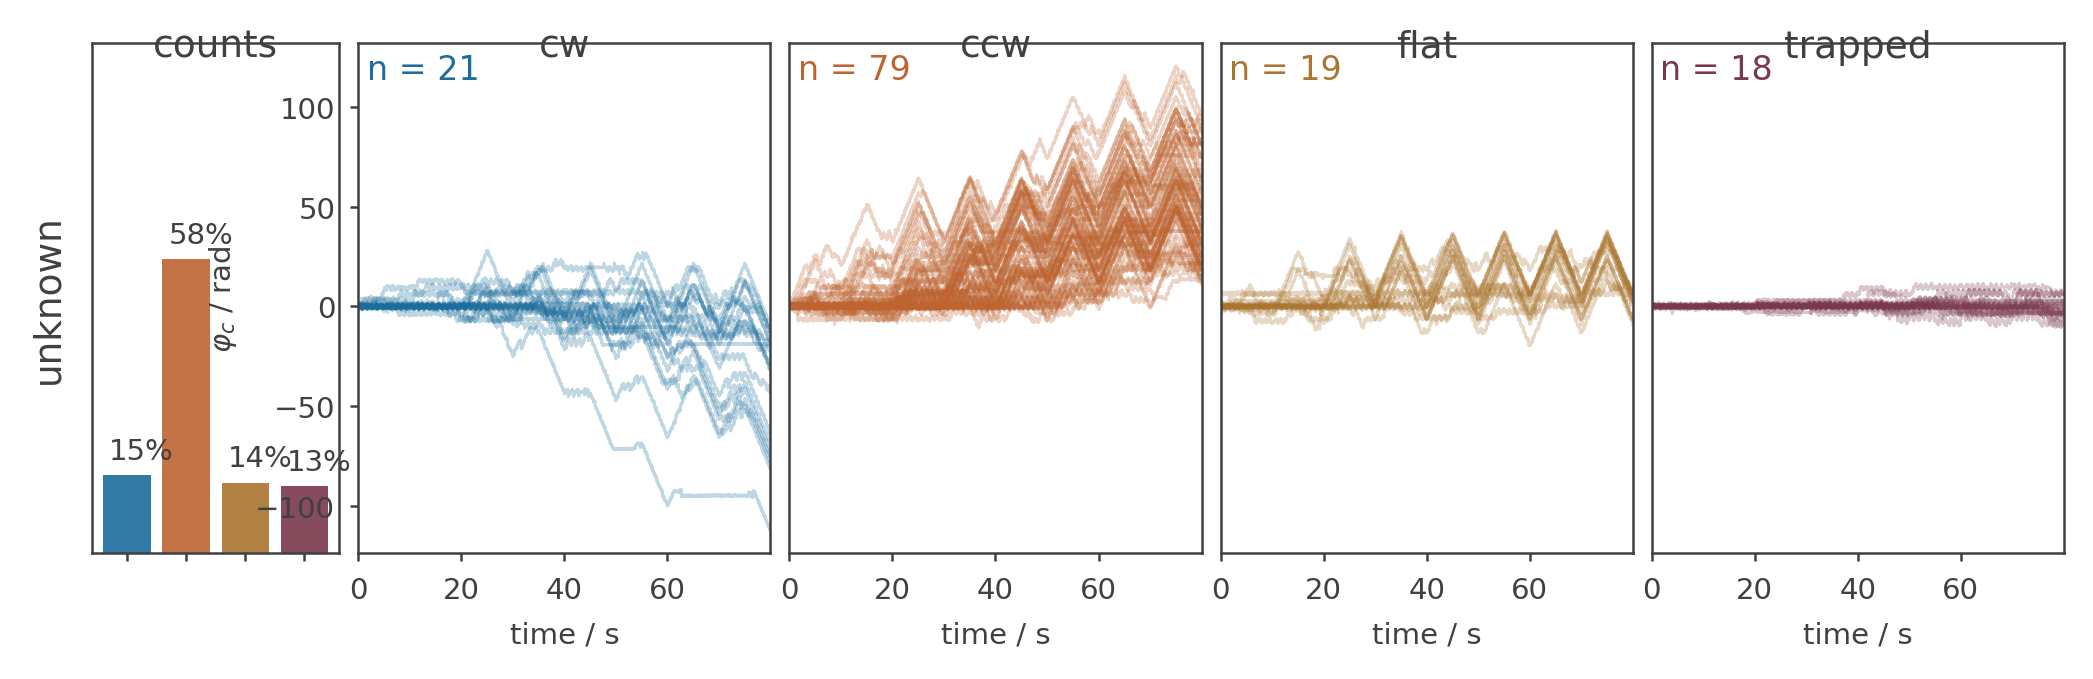

In [11]:
# SI Figure
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

TWO_PI = 2*np.pi
try:
    from cmcrameri import cm as cmc
    _vik = cmc.vik
except Exception:
    _vik = plt.cm.get_cmap("coolwarm")

# subset colors (used for bars and trajectories)
SUBSET_COLORS = {
    "cw":  _vik(0.22),                # blue-ish
    "ccw": _vik(0.78),                # orange-ish
    "flat": '#AA752F',  # yxellow
    "trapped": '#79384C' # brombeer
}

# ---- optional-QC shim: if QC columns are missing, treat all particles as passing ----
def _flags_df(m, ids):
    import pandas as pd
    df = getattr(m, "particle_data", None)
    if not isinstance(df, pd.DataFrame):
        return pd.Series(True, index=ids), pd.Series(True, index=ids)
    if df.index.name != "particle":
        try:
            df.index = df.index.astype(int)
        except Exception:
            pass
        df.index.name = "particle"
    sub = df.reindex(ids)
    r = sub["rho_within_limits"] if "rho_within_limits" in sub.columns else pd.Series(1, index=ids)
    e = sub["energy_metastable"] if "energy_metastable" in sub.columns else pd.Series(1, index=ids)
    r_ok = pd.to_numeric(r, errors="coerce").fillna(1).astype("Int8").eq(1)
    e_ok = pd.to_numeric(e, errors="coerce").fillna(1).astype("Int8").eq(1)
    return r_ok, e_ok


# ---------- classification (3π logic) ----------
def _unwrapped_span_over(m, pid, t0, t1):
    t, yu = _traj_unwrapped(m, int(pid))
    if t is None: return np.nan
    a, b = max(t0, t[0]), min(t1, t[-1])
    if b <= a: return np.nan
    mask = (t>=a) & (t<=b)
    if np.count_nonzero(mask) < 2:
        ya = _interp(t, yu, a); yb = _interp(t, yu, b)
        return float(abs(yb-ya))
    ywin = yu[mask]
    return float(np.nanmax(ywin) - np.nanmin(ywin))

def _classify_subsets_one_m(m, reference_freq_hz, *,
                            span_thresh=TWO_PI,
                            final_abs_min_rad=3*np.pi,
                            final_use_relative=False):
    """
    flat      : |Δφ_net| < 3π  AND  |Δφ_ccw| ≥ 3π  AND  |Δφ_cw| ≥ 3π
    trapped   : |Δφ_net| < 3π  AND  (|Δφ_ccw| < 3π OR |Δφ_cw| < 3π)
    cw        : Δφ_net < 0
    ccw       : Δφ_net > 0
    """
    proto = getattr(m, "protocol", {})
    rb = _get2(proto.get("rot-both", None))
    if rb is None:
        return {k: pd.Index([], name="particle") for k in ("cw","ccw","flat","trapped")}
    t0, t1 = rb
    volts = _voltages(proto)

    base = _base_ids_present_and_whitelist(m)
    if base.empty:
        return {k: pd.Index([], name="particle") for k in ("cw","ccw","flat","trapped")}
    r_ok, e_ok = _flags_df(m, base)
    ids = base[(r_ok.fillna(False) & e_ok.fillna(False)).values]

    out = {k: [] for k in ("cw","ccw","flat","trapped")}
    for p in ids:
        span = _unwrapped_span_over(m, p, t0, t1)
        if not np.isfinite(span) or span < float(span_thresh):
            out["trapped"].append(int(p)); continue

        t, yu = _traj_unwrapped(m, p)
        if t is None:
            out["trapped"].append(int(p)); continue

        rows=[]
        for V in volts:
            for tag in ("ccw","cw"):
                w = _get2(proto.get(f"{V}V-{tag}", None))
                if w is None: continue
                a, b = max(w[0], t[0]), min(w[1], t[-1])
                if b <= a: continue
                ya = _interp(t, yu, a); yb = _interp(t, yu, b)
                rows.append(dict(V=int(V), tag=tag, T=(b-a), dphi=float(yb-ya)))
        halves = pd.DataFrame(rows, columns=["V","tag","T","dphi"]).dropna()
        if halves.empty:
            out["trapped"].append(int(p)); continue

        dphi_net = float(halves["dphi"].sum())
        ccw_mask = halves["tag"].str.lower().eq("ccw")
        cw_mask  = halves["tag"].str.lower().eq("cw")
        mag_ccw  = float(np.sum(np.abs(halves.loc[ccw_mask,"dphi"]))) if ccw_mask.any() else 0.0
        mag_cw   = float(np.sum(np.abs(halves.loc[cw_mask, "dphi"]))) if cw_mask.any()  else 0.0

        small_net = abs(dphi_net) < float(final_abs_min_rad)
        moved_ccw = mag_ccw >= float(final_abs_min_rad)
        moved_cw  = mag_cw  >= float(final_abs_min_rad)

        if small_net:
            if moved_ccw and moved_cw:
                out["flat"].append(int(p))
            else:
                out["trapped"].append(int(p))
        else:
            out["cw" if dphi_net < 0 else "ccw"].append(int(p))
            
        m.particle_data.loc[int(p), 'class'] = ('flat' if (small_net and moved_ccw and moved_cw) else ('trapped' if small_net else ('cw' if dphi_net < 0 else 'ccw')))

    return {k: pd.Index(v, name="particle") for k,v in out.items()}

def _gather_subset_traces_for_variant(ms, subset_name, *,
                                      span_thresh, final_abs_min_rad, final_use_relative,
                                      reference_freq_hz, max_per_subset=150, rng=None):
    if rng is None: rng = np.random.default_rng(1234)
    segs=[]; used=0
    for m in ms:
        proto = getattr(m, "protocol", {})
        rb = _get2(proto.get("rot-both", None))
        if rb is None: continue
        t0,t1 = rb
        subs = _classify_subsets_one_m(m, reference_freq_hz,
                                       span_thresh=span_thresh,
                                       final_abs_min_rad=final_abs_min_rad,
                                       final_use_relative=final_use_relative)
        ids = list(subs.get(subset_name, pd.Index([])))
        if not ids: continue
        if used >= max_per_subset: break
        k = min(len(ids), max_per_subset-used)
        pick = rng.choice(ids, size=k, replace=False)

        for p in pick:
            t, yu = _traj_unwrapped(m, p)
            if t is None: continue
            a, b = max(t0,t[0]), min(t1,t[-1])
            if b <= a: continue
            ya = _interp(t, yu, a)
            mask = (t>=a) & (t<=b)
            if np.count_nonzero(mask) >= 2:
                tr = t[mask] - t0
                yr = yu[mask] - ya
            else:
                yb = _interp(t, yu, b)
                tr = np.array([0.0, b-a]); yr = np.array([0.0, yb-ya])
            segs.append((tr, yr))
            used += 1
            if used >= max_per_subset: break
    return segs


def plot_paper_counts_and_trajectories_vertical(
    m_list,
    *,
    reference_freq_hz=1.0,
    span_thresh=TWO_PI,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,
    variants_ignore=("F",),
    max_per_subset=170,
    width_mm=175, height_mm=200,
    display_dpi=300,
    save_path=None
):
    # group by variant (ignore some)
    by_var={}
    for m in m_list:
        var = getattr(m, "variant", "unknown")
        if var in variants_ignore: 
            continue
        by_var.setdefault(var, []).append(m)
    variants = sorted(by_var.keys())
    if not variants:
        print("No variants to plot."); 
        return

    # ---------- precompute counts, segments, and true limits ----------
    per_var_counts, per_var_segs, per_var_ylim, per_var_xlim = {}, {}, {}, {}
    for i, var in enumerate(variants):
        ms = by_var[var]

        # absolute counts
        counts = dict(cw=0, ccw=0, flat=0, trapped=0)
        for m in ms:
            subs = _classify_subsets_one_m(
                m, reference_freq_hz,
                span_thresh=span_thresh,
                final_abs_min_rad=final_abs_min_rad,
                final_use_relative=final_use_relative
            )
            for k in counts: 
                counts[k] += int(len(subs[k]))
        per_var_counts[var] = counts

        # gather segments + true limits
        segs_by_subset = {}
        y_min, y_max, t_max = np.inf, -np.inf, 0.0
        for subset in ("cw","ccw","flat","trapped"):
            segs = _gather_subset_traces_for_variant(
                ms, subset,
                span_thresh=span_thresh,
                final_abs_min_rad=final_abs_min_rad,
                final_use_relative=final_use_relative,
                reference_freq_hz=reference_freq_hz,
                max_per_subset=max_per_subset,
                rng=np.random.default_rng(1234+i)
            )
            segs_by_subset[subset] = segs
            for tr, yr in segs:
                if yr.size:
                    y_min = min(y_min, float(np.nanmin(yr)))
                    y_max = max(y_max, float(np.nanmax(yr)))
                if tr.size:
                    t_max = max(t_max, float(np.nanmax(tr)))

        if not np.isfinite(y_min) or not np.isfinite(y_max) or y_min == y_max:
            y_min, y_max = -3*TWO_PI, 3*TWO_PI
        pad = 0.05*(y_max - y_min)
        per_var_ylim[var] = (y_min - pad, y_max + pad)
        per_var_segs[var] = segs_by_subset
        per_var_xlim[var] = (0.0, t_max if t_max>0 else None)

    # ---------- layout ----------
    mm2in = 1/25.4
    figsize = (width_mm*mm2in, height_mm*mm2in)
    with mpl.rc_context(PAPER_RC):
        fig = plt.figure(figsize=figsize, dpi=display_dpi)
        gs = fig.add_gridspec(
            nrows=len(variants), ncols=5,
            width_ratios=[0.6, 1, 1, 1, 1],
            height_ratios=[1]*len(variants),
            left=0.036, right=0.99, top=0.965, bottom=0.10,
            wspace=0.05, hspace=0.025
        )

        # column titles
        for j, title in enumerate(["counts", "cw", "ccw", "flat", "trapped"]):
            x0, x1 = gs.get_grid_positions(fig)[2][j], gs.get_grid_positions(fig)[3][j]
            fig.text(0.5*(x0+x1), 0.988, title, ha="center", va="top", color="0.25", fontsize=9)

        # ---------- rows ----------
        for ri, var in enumerate(variants):
            segs_by_subset = per_var_segs[var]
            ylo,yhi = per_var_ylim[var]
            xlo,xhi = per_var_xlim[var]
            counts   = per_var_counts[var]

            # ---- bar column (fractions, no y-ticks/label) ----
            axB = fig.add_subplot(gs[ri, 0]); _style_ax(axB)
            cats  = ["cw","ccw","flat","trapped"]
            raw   = [counts[c] for c in cats]
            tot   = max(1, sum(raw))
            fracs = [v/tot for v in raw]
            x     = np.arange(len(cats))
            axB.bar(x, fracs, color=[SUBSET_COLORS[c] for c in cats],
                    alpha=0.9, width=0.8, edgecolor="none")
            axB.set_ylim(0, 1)                  # <- strict 0..1
            axB.set_yticks([])                  # <- no ticks
            axB.set_ylabel("")                  # <- no label
            axB.set_xticks(x); axB.set_xticklabels([])
            axB.grid(False)

            # % labels (nudged left a bit)
            for xi, frac in zip(x, fracs):
                axB.text(xi-0.30, min(0.98, frac+0.02), f"{int(round(frac*100))}%",
                         ha="left", va="bottom", fontsize=7, color="0.25", clip_on=False)

            # ---- trajectories + n annotations ----
            for ci, subset in enumerate(["cw","ccw","flat","trapped"], start=1):
                ax = fig.add_subplot(gs[ri, ci]); _style_ax(ax)
                col = SUBSET_COLORS[subset]

                # traces
                for tr, yr in segs_by_subset.get(subset, []):
                    ax.plot(tr, yr, color=col, alpha=0.28, lw=0.65)

                ax.set_ylim(ylo, yhi)
                if xhi is not None: ax.set_xlim(xlo, xhi)

                # n-annotation (absolute count) at top-left
                ax.text(0.02, 0.98, f"n = {counts.get(subset, 0)}",
                        transform=ax.transAxes, ha="left", va="top",
                        color=col, fontsize=8)

                # tidy ticks
                if ci == 1:
                    ax.set_ylabel(r"$\varphi_c$ / rad")
                    ax.tick_params(axis="y", which="both", length=2.0)
                else:
                    ax.set_yticklabels([]); ax.tick_params(axis="y", length=0)

                if ri == len(variants)-1:
                    ax.set_xlabel("time / s")
                    ax.tick_params(axis="x", which="both", length=2.0)
                else:
                    ax.set_xticklabels([]); ax.tick_params(axis="x", length=0)

            # row label (variant) on far left
            rowbox = gs[ri,0].get_position(fig)
            fig.text(0.006, 0.5*(rowbox.y0+rowbox.y1), var,
                    ha="left", va="center", rotation=90,
                    fontsize=9, color="0.25")

        if save_path:
            fig.savefig(save_path, bbox_inches="tight", pad_inches=0)
        plt.show()



plot_paper_counts_and_trajectories_vertical(
    m_list,
    reference_freq_hz=1.0,
    span_thresh=4*np.pi,         # tiny-span → trapped
    final_abs_min_rad=3*np.pi,   # 3π rule
    final_use_relative=False,
    max_per_subset=170,
    width_mm=175, height_mm=50,
    display_dpi=300,
    save_path=None,
)


In [12]:
change_particle_labels(m_list, "ccw", [106,137,143,131,147,37], m_index=0)
change_particle_labels(m_list, "cw", [2], m_index=0)
change_particle_labels(m_list, "trapped", [7,97,250,204], m_index=0)
change_particle_labels(m_list, "flat", [176], m_index=0)

m=0, p=106: flat -> ccw
m=0, p=137: flat -> ccw
m=0, p=143: flat -> ccw
m=0, p=131: flat -> ccw
m=0, p=147: ccw -> ccw
m=0, p=37: flat -> ccw
m=0, p=2: nan -> cw
m=0, p=7: flat -> trapped
m=0, p=97: nan -> trapped
m=0, p=250: flat -> trapped
m=0, p=204: flat -> trapped
m=0, p=176: cw -> flat


### Plot rotor gallery

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from math import ceil


def plot_particle_classes(
    m_list,
    *,
    particle_classes=("cw", "ccw", "flat", "trapped"),
    m_indices=None,
    particles=None,
    ncols=5,
    nrows=4,
    max_per_class=None,
    panel_width_mm=36,
    panel_height_mm=28,
    shared_ylim=None,
    shared_xlim=None,
    y_ticks=None,
    y_tick_spacing=10,
    x_ticks=None,
    x_tick_spacing=None,
    sort_by="abs_final",
    show_particle_id=False,
    show_manual_marker=False,
    line_lw=0.85,
    fontsize=7,
    tick_fontsize=5.8,
    axis_label_size=7,
    title_fontsize=7,
    save_dir=None,
    save_prefix="rotation_gallery_outer",
    save_png=True,
    save_svg=False,
    dpi=300,
):
    """
    Paginated gallery of unwrapped rotor trajectories during 'rot-both'.

    One gallery per particle class.

    Y-axis limits:
        None:
            Automatically determine separate shared limits for each class.

        Tuple (ymin, ymax):
            Use the same limits for all classes.

        Dictionary:
            Specify limits individually, e.g.
            {
                "cw": (-100, 10),
                "ccw": (-10, 100),
                "flat": (-30, 30),
                "trapped": (-10, 10),
            }

    Y-axis ticks:
        None:
            Automatically generate ticks using y_tick_spacing.

        Sequence:
            Use the same explicit ticks for all classes.

        Dictionary:
            Specify ticks separately for each class.

    Sorting:
        "abs_final": descending absolute final cumulative turns
        "final": descending signed final cumulative turns
        "ascending": ascending signed final cumulative turns
        "particle": ascending particle ID
        None: original order

    Returns:
        DataFrame with measurement index, particle ID, class,
        final turns, rank, and page.
    """

    # =====================================================================
    # INPUTS
    # =====================================================================

    if isinstance(particle_classes, str):
        particle_classes = (particle_classes,)

    if isinstance(m_indices, (int, np.integer)):
        m_indices = (int(m_indices),)

    if particles is not None:
        particles = set(map(int, particles))

    valid_classes = ("cw", "ccw", "flat", "trapped")
    invalid = set(particle_classes) - set(valid_classes)

    if invalid:
        raise ValueError(f"Unknown particle classes: {invalid}")

    if sort_by not in ("abs_final", "final", "ascending", "particle", None):
        raise ValueError("Invalid sort_by value.")

    ncols, nrows = int(ncols), int(nrows)

    if ncols < 1 or nrows < 1:
        raise ValueError("ncols and nrows must be positive.")

    if y_tick_spacing is not None and y_tick_spacing <= 0:
        raise ValueError("y_tick_spacing must be positive.")

    if x_tick_spacing is not None and x_tick_spacing <= 0:
        raise ValueError("x_tick_spacing must be positive.")

    page_size = ncols * nrows

    colors = dict(
        globals().get(
            "PARTICLE_COLORS",
            globals().get("SUBSET_COLORS", {}),
        )
    )

    defaults = {
        "cw": "#497B9D",
        "ccw": "#B66C63",
        "flat": "#AA752F",
        "trapped": "#79384C",
    }

    for key, color in defaults.items():
        colors.setdefault(key, color)

    # =====================================================================
    # COLLECT TRAJECTORIES
    # =====================================================================

    records = []
    trajectories = {}

    for mi, m in enumerate(m_list):

        if m_indices is not None and mi not in m_indices:
            continue

        df = getattr(m, "particle_data", None)

        if not isinstance(df, pd.DataFrame) or "class" not in df.columns:
            continue

        window = _get2(
            getattr(m, "protocol", {}).get("rot-both", None)
        )

        if window is None:
            continue

        t0, t1 = window

        for pid, label in df["class"].items():

            if label not in particle_classes:
                continue

            pid = int(pid)

            if particles is not None and pid not in particles:
                continue

            t, phi = _traj_unwrapped(m, pid)

            if t is None or phi is None:
                continue

            t = np.asarray(t, dtype=float)
            phi = np.asarray(phi, dtype=float)

            mask = (
                (t >= t0)
                & (t <= t1)
                & np.isfinite(t)
                & np.isfinite(phi)
            )

            if np.count_nonzero(mask) < 2:
                continue

            tt = t[mask] - t0
            yy = (phi[mask] - phi[mask][0]) / (2*np.pi)

            final_turns = float(yy[-1])

            manual = (
                df.loc[pid, "class_manual"]
                if "class_manual" in df.columns
                else pd.NA
            )

            key = (mi, pid)
            trajectories[key] = (tt, yy)

            records.append({
                "m_index": mi,
                "particle": pid,
                "class": label,
                "manual": bool(pd.notna(manual)),
                "final_turns": final_turns,
                "abs_final_turns": abs(final_turns),
            })

    df_review = pd.DataFrame(
        records,
        columns=[
            "m_index", "particle", "class", "manual",
            "final_turns", "abs_final_turns",
        ],
    )

    if df_review.empty:
        print("No matching particle trajectories found.")
        return df_review

    # =====================================================================
    # SORT WITHIN EACH CLASS
    # =====================================================================

    sorted_groups = []

    for particle_class in particle_classes:

        sub = df_review[
            df_review["class"].eq(particle_class)
        ].copy()

        if sub.empty:
            continue

        if sort_by == "abs_final":
            sub = sub.sort_values(
                ["abs_final_turns", "m_index", "particle"],
                ascending=[False, True, True],
                kind="stable",
            )

        elif sort_by == "final":
            sub = sub.sort_values(
                ["final_turns", "m_index", "particle"],
                ascending=[False, True, True],
                kind="stable",
            )

        elif sort_by == "ascending":
            sub = sub.sort_values(
                ["final_turns", "m_index", "particle"],
                ascending=[True, True, True],
                kind="stable",
            )

        elif sort_by == "particle":
            sub = sub.sort_values(
                ["particle", "m_index"],
                ascending=True,
                kind="stable",
            )

        if max_per_class is not None:
            sub = sub.head(int(max_per_class))

        sub = sub.reset_index(drop=True)
        sub["rank"] = np.arange(1, len(sub) + 1)

        sorted_groups.append(sub)

    df_review = pd.concat(sorted_groups, ignore_index=True)

    # =====================================================================
    # SHARED X LIMITS ACROSS ALL CLASSES
    # =====================================================================

    keys = list(
        zip(df_review["m_index"], df_review["particle"])
    )

    if shared_xlim is None:
        xmax = max(
            np.nanmax(trajectories[key][0])
            for key in keys
        )
        shared_xlim = (0.0, max(float(xmax), 1.0))

    # =====================================================================
    # INDIVIDUAL SHARED Y LIMITS FOR EACH CLASS
    # =====================================================================

    class_ylims = {}
    class_yticks = {}

    for particle_class in particle_classes:

        sub = df_review[
            df_review["class"].eq(particle_class)
        ]

        if sub.empty:
            continue

        class_keys = list(
            zip(sub["m_index"], sub["particle"])
        )

        # -------------------------------------------------------------
        # Explicit limits, if supplied
        # -------------------------------------------------------------

        if isinstance(shared_ylim, dict):
            ylim = shared_ylim.get(particle_class, None)
        else:
            ylim = shared_ylim

        # -------------------------------------------------------------
        # Automatic limits for this class only
        # -------------------------------------------------------------

        if ylim is None:

            ymin = min(
                np.nanmin(trajectories[key][1])
                for key in class_keys
            )

            ymax = max(
                np.nanmax(trajectories[key][1])
                for key in class_keys
            )

            if y_tick_spacing is not None:
                step = float(y_tick_spacing)

                ymin = np.floor(ymin / step) * step
                ymax = np.ceil(ymax / step) * step

            else:
                padding = 0.05 * max(ymax-ymin, 1.0)
                ymin -= padding
                ymax += padding

            if ymin == ymax:
                ymin -= 1
                ymax += 1

            ylim = (float(ymin), float(ymax))

        class_ylims[particle_class] = tuple(ylim)

        # -------------------------------------------------------------
        # Class-specific tick positions
        # -------------------------------------------------------------

        if isinstance(y_ticks, dict):
            ticks = y_ticks.get(particle_class, None)
        else:
            ticks = y_ticks

        if ticks is None and y_tick_spacing is not None:
            step = float(y_tick_spacing)

            ticks = np.arange(
                np.ceil(ylim[0] / step) * step,
                ylim[1] + 0.5 * step,
                step,
            )

        class_yticks[particle_class] = (
            np.asarray(ticks, dtype=float)
            if ticks is not None
            else None
        )

    # =====================================================================
    # X TICKS
    # =====================================================================

    if x_ticks is not None:
        xticks = np.asarray(x_ticks, dtype=float)

    elif x_tick_spacing is not None:
        step = float(x_tick_spacing)

        xticks = np.arange(
            np.ceil(shared_xlim[0] / step) * step,
            shared_xlim[1] + 0.5 * step,
            step,
        )

    else:
        xticks = None

    # =====================================================================
    # AXIS STYLE
    # =====================================================================

    def style_axis(ax):

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(
            length=2,
            width=0.6,
            direction="out",
            pad=1.4,
            labelsize=tick_fontsize,
        )

        ax.grid(False)

    # =====================================================================
    # PAGINATED PLOTTING
    # =====================================================================

    output_records = []

    with plt.rc_context({
        "font.size": fontsize,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "DejaVu Sans"],
        "axes.linewidth": 0.6,
        "svg.fonttype": "none",
    }):

        for particle_class in particle_classes:

            sub = df_review[
                df_review["class"].eq(particle_class)
            ].reset_index(drop=True)

            if sub.empty:
                continue

            ylim = class_ylims[particle_class]
            yticks = class_yticks[particle_class]

            n_pages = ceil(len(sub) / page_size)

            for page in range(n_pages):

                page_sub = sub.iloc[
                    page*page_size:(page+1)*page_size
                ].copy()

                n_on_page = len(page_sub)

                fig, axes = plt.subplots(
                    nrows,
                    ncols,
                    figsize=(
                        panel_width_mm*ncols / 25.4,
                        panel_height_mm*nrows / 25.4,
                    ),
                    squeeze=False,
                    sharex=True,
                    sharey=True,
                )

                # -----------------------------------------------------
                # Individual rotor panels
                # -----------------------------------------------------

                for index, row in enumerate(
                    page_sub.itertuples(index=False)
                ):

                    r = index // ncols
                    c = index % ncols
                    ax = axes[r, c]

                    tt, yy = trajectories[
                        (row.m_index, row.particle)
                    ]

                    ax.plot(
                        tt,
                        yy,
                        color=colors[particle_class],
                        lw=line_lw,
                        solid_capstyle="round",
                    )

                    ax.set_xlim(*shared_xlim)
                    ax.set_ylim(*ylim)

                    if yticks is not None:
                        ax.set_yticks(yticks)

                    if xticks is not None:
                        ax.set_xticks(xticks)

                    if show_particle_id:

                        title = f"p={row.particle}"

                        if show_manual_marker and row.manual:
                            title += " *"

                        ax.set_title(
                            title,
                            fontsize=title_fontsize,
                            pad=3,
                        )

                    style_axis(ax)

                    # Y labels only in first column.
                    if c == 0:
                        ax.set_ylabel(
                            "turns",
                            fontsize=axis_label_size,
                        )
                        ax.tick_params(
                            axis="y",
                            left=True,
                            labelleft=True,
                        )
                    else:
                        ax.tick_params(
                            axis="y",
                            left=False,
                            labelleft=False,
                        )

                    output_records.append({
                        "m_index": row.m_index,
                        "particle": row.particle,
                        "class": particle_class,
                        "manual": row.manual,
                        "final_turns": row.final_turns,
                        "abs_final_turns": row.abs_final_turns,
                        "rank": row.rank,
                        "page": page + 1,
                    })

                # -----------------------------------------------------
                # Hide unused panels
                # -----------------------------------------------------

                for index in range(n_on_page, page_size):
                    axes.flat[index].axis("off")

                # -----------------------------------------------------
                # X labels only in lowest occupied row per column
                # -----------------------------------------------------

                for c in range(ncols):

                    occupied = [
                        r for r in range(nrows)
                        if r*ncols+c < n_on_page
                    ]

                    if not occupied:
                        continue

                    last_r = occupied[-1]

                    for r in occupied:

                        ax = axes[r, c]
                        is_bottom = r == last_r

                        ax.tick_params(
                            axis="x",
                            bottom=is_bottom,
                            labelbottom=is_bottom,
                        )

                        if is_bottom:
                            ax.set_xlabel(
                                "time / s",
                                fontsize=axis_label_size,
                            )
                        else:
                            ax.set_xlabel("")

                fig.subplots_adjust(
                    left=0.085,
                    right=0.99,
                    bottom=0.075,
                    top=0.98,
                    wspace=0.12,
                    hspace=(
                        0.35 if show_particle_id else 0.22
                    ),
                )

                # No titles or grid lines.

                # -----------------------------------------------------
                # Save
                # -----------------------------------------------------

                if save_dir is not None:

                    path = Path(save_dir)
                    path.mkdir(parents=True, exist_ok=True)

                    filename = (
                        f"{save_prefix}_{particle_class}"
                        f"_page_{page+1:03d}"
                    )

                    if save_png:
                        fig.savefig(
                            path / f"{filename}.png",
                            dpi=dpi,
                            bbox_inches="tight",
                        )

                    if save_svg:
                        fig.savefig(
                            path / f"{filename}.svg",
                            bbox_inches="tight",
                        )

                plt.show()
                plt.close(fig)

    return pd.DataFrame(output_records)

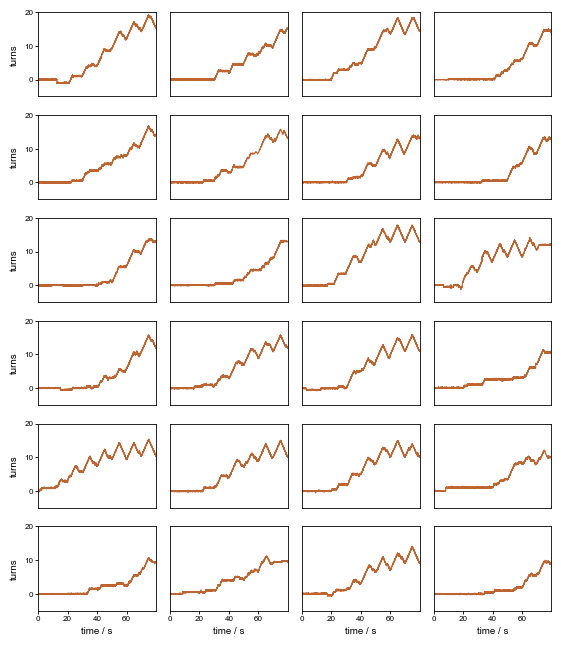

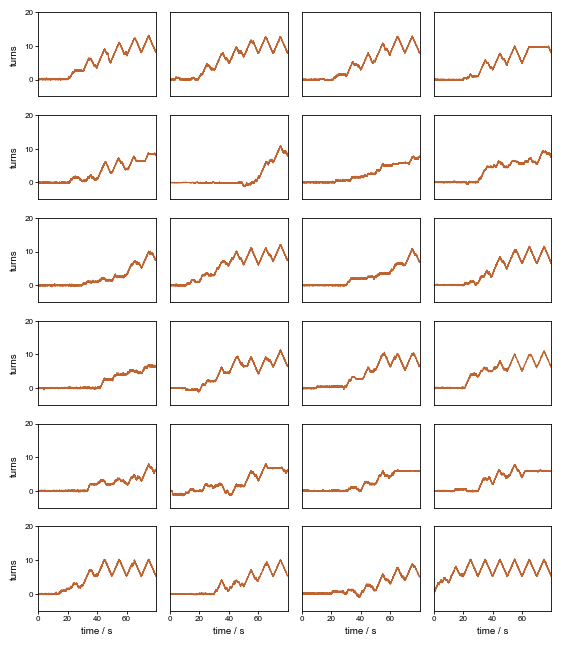

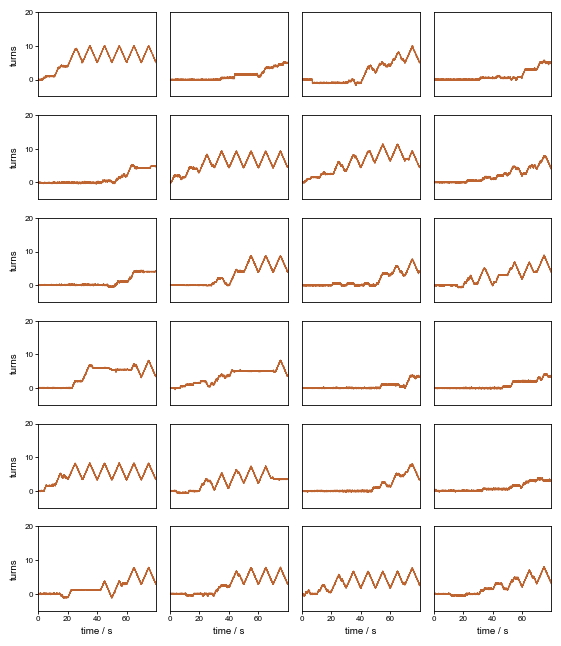

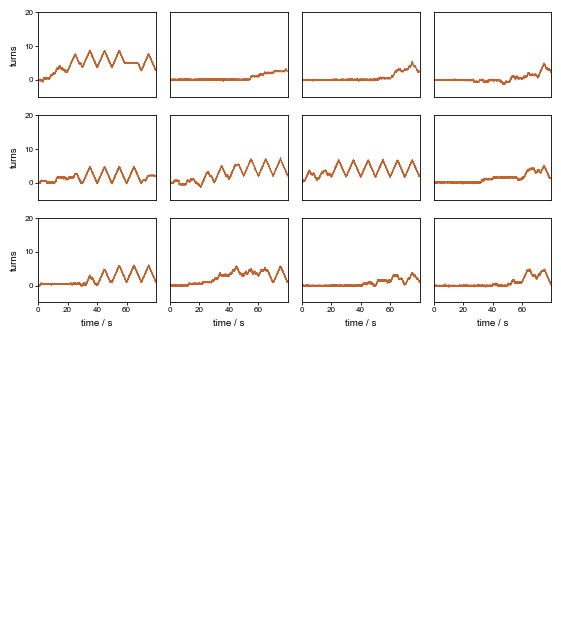

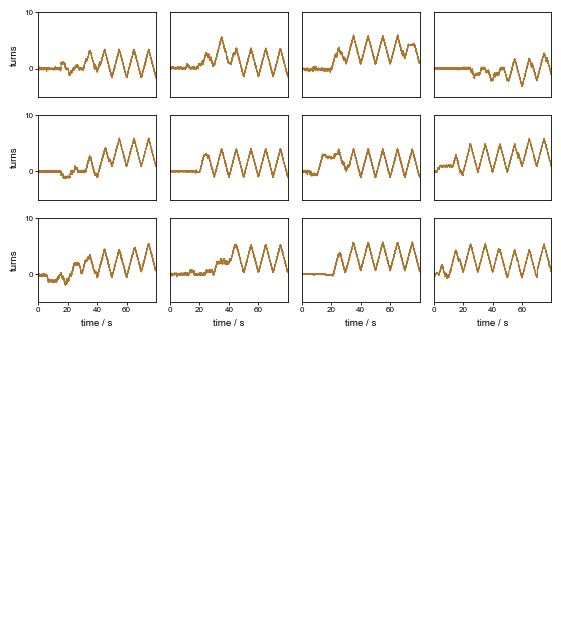

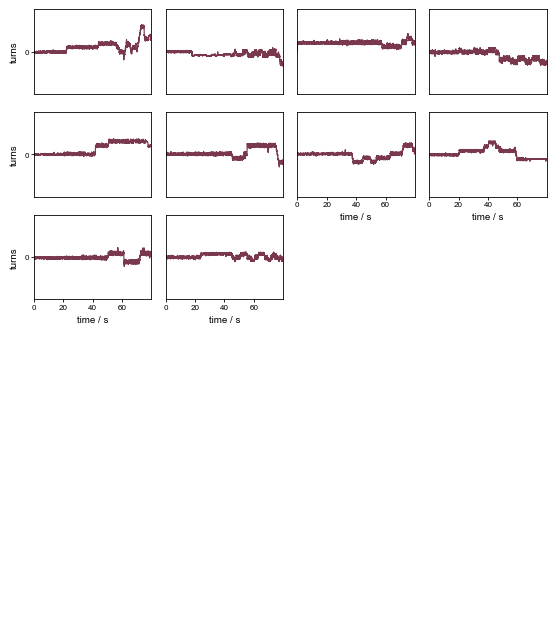

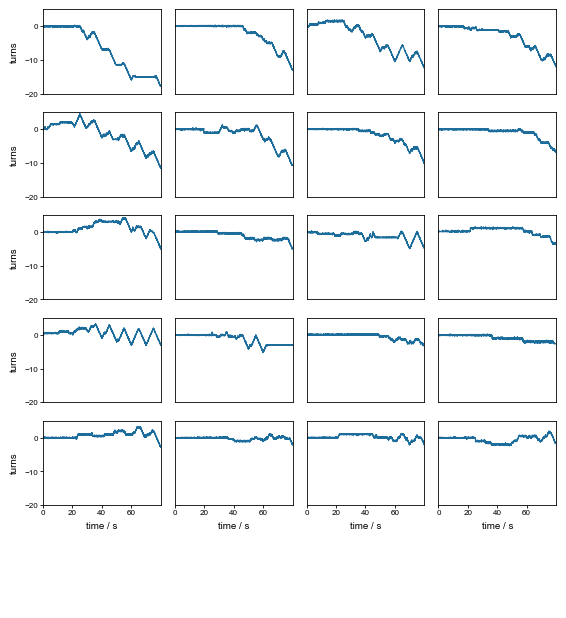

In [14]:
_ = plot_particle_classes(
    m_list,
    particle_classes=("ccw", "flat", "trapped","cw"),
    m_indices=None,
    particles=None,
    ncols=4,
    nrows=6,
    max_per_class=None,
    panel_width_mm=36,
    panel_height_mm=28,

    # Automatically determine one shared y-range per class.
    # shared_ylim=None,

    # Alternatively, manually specify each class:
    shared_ylim={
        "cw": (-20, 5),
        "ccw": (-5, 20),
        "flat": (-5, 7),
        "trapped": (-5, 5),},

    shared_xlim=None,

    y_ticks=None,
    y_tick_spacing=10,
    x_ticks=None,
    x_tick_spacing=None,

    sort_by="abs_final",
    show_particle_id=False,
    show_manual_marker=False,

    line_lw=0.85,
    save_dir=r'R:\_06__Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_4',
    save_png=True,
    save_svg=False,
    dpi=300,
)

### Plot summary figure

In [15]:
# =============================================================================
# TWO-PANEL CCW TRANSPORT FIGURE — UMBRELLA-PAPER STYLE
#
# a | trajectories
#       - all rotors transparent light gray
#       - 1 CCW rotor with maximum positive advancement
#       - 1 exemplary CW rotor in light green
#       - 1 exemplary flat rotor in blue
#       - 1 exemplary trapped rotor in warm gold
#       - dashed ±1 Hz reference trajectory from protocol
#
# b | rotor-class fractions
#
# Only trajectories and class fractions are computed; no activity DataFrames.
#
# Uses existing helpers from your analysis:
#   _classify_subsets_one_m
#   _traj_unwrapped
#   _interp
#   _get2
#   _style_ax
#   PAPER_RC
#   TWO_PI
# =============================================================================

import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path


# =============================================================================
# DEFAULT COLORS
# =============================================================================

CK_colors = {
    "orange": (215/255, 131/255, 41/255),
    "beige": (225/255, 209/255, 180/255),
    "gold": (226/255, 172/255, 72/255),
    "olive": (140/255, 135/255, 59/255),
    "offwhite": (222/255, 224/255, 213/255),
    "palecyan": (167/255, 197/255, 197/255),
    "darkcyan": (105/255, 155/255, 155/255),
    "lightblue": (73/255, 139/255, 167/255),
    "darkblue": (46/255, 89/255, 108/255),
    "darkred": (102/255, 27/255, 35/255),
    "grey": (0.25, 0.25, 0.25),
    "midgrey": (0.45, 0.45, 0.45),
    "lightgrey": (0.72, 0.72, 0.72),
    "black": (0, 0, 0),
    "white": (1, 1, 1),
    "warmgold": (198/255, 161/255, 91/255),
    "target_teal": (111/255, 166/255, 166/255),
    "free_grey": (201/255, 201/255, 201/255),
    "fit_darkgrey": (46/255, 46/255, 46/255),
}
CCW_COLORS = (CK_colors["darkcyan"],)
CW_COLOR = CK_colors["target_teal"]
FLAT_COLOR = CK_colors["lightblue"]
TRAPPED_COLOR = CK_colors["warmgold"]
ENSEMBLE_GRAY = CK_colors["lightgrey"]

# Manuscript typography: override values here if PAPER_RC uses different sizes.
FIGURE_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "mathtext.fontset": "dejavusans",
    "mathtext.default": "regular",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 150,
    "savefig.dpi": 300,
}



# =============================================================================
# SMALL HELPERS
# =============================================================================

def _cwccw_windows(proto):
    """Return alternating CW/CCW protocol windows as (t0, t1, direction)."""
    wins = []

    for key, value in getattr(proto, "items", lambda: [])():
        if not (isinstance(value, (list, tuple)) and len(value) >= 2):
            continue

        s = str(key).lower()

        if "both" in s:
            continue

        if "ccw" in s:
            wins.append((float(value[0]), float(value[1]), +1.0))
        elif "cw" in s:
            wins.append((float(value[0]), float(value[1]), -1.0))

    wins.sort(key=lambda z: z[0])
    return wins


def _voltage_windows(proto):
    """Return one combined interval for every V-ccw/V-cw pair."""
    by_voltage = {}

    for key, w in getattr(proto, "items", lambda: [])():
        m = re.match(r"^\s*(\d+)\s*V-(cw|ccw)\s*$", str(key), flags=re.IGNORECASE)

        if m is None or not (isinstance(w, (list, tuple)) and len(w) >= 2):
            continue

        V = int(m.group(1))
        by_voltage.setdefault(V, []).append((float(w[0]), float(w[1])))

    out = []

    for V, segs in by_voltage.items():
        t0 = min(x[0] for x in segs)
        t1 = max(x[1] for x in segs)
        out.append((t0, t1, V))

    return sorted(out, key=lambda z: z[0])


def _extract_classified_data_one_m(
    m,
    *,
    m_index,
    reference_freq_hz=1.0,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,
):
    """Classify one measurement and extract trajectories + directional response."""

    proto = getattr(m, "protocol", {})
    rb = _get2(proto.get("rot-both", None))

    subsets = _classify_subsets_one_m(
        m,
        reference_freq_hz,
        span_thresh=span_thresh,
        final_abs_min_rad=final_abs_min_rad,
        final_use_relative=final_use_relative,
    )

    trajectories = []

    if rb is not None:
        t0, t1 = rb

        for rotor_class in ("cw", "ccw", "flat", "trapped"):
            for pid in subsets.get(rotor_class, pd.Index([])):
                t, yu = _traj_unwrapped(m, int(pid))

                if t is None:
                    continue

                a, b = max(t0, t[0]), min(t1, t[-1])

                if b <= a:
                    continue

                ya = _interp(t, yu, a)
                mask = (t >= a) & (t <= b)

                if np.count_nonzero(mask) >= 2:
                    tr = np.asarray(t[mask] - t0, float)
                    yr = np.asarray(yu[mask] - ya, float)
                else:
                    yb = _interp(t, yu, b)
                    tr = np.asarray([0.0, b-a], float)
                    yr = np.asarray([0.0, yb-ya], float)

                # Directional displacement within the driven protocol windows.
                # Use the original unwrapped trajectory, not its net endpoint.
                ccw_forward = 0.0
                cw_backward = 0.0
                for w0, w1, direction in _cwccw_windows(proto):
                    wa, wb = max(w0, t[0]), min(w1, t[-1])
                    if wb <= wa:
                        continue
                    delta = float(_interp(t, yu, wb) - _interp(t, yu, wa))
                    if direction > 0:
                        ccw_forward += delta
                    else:
                        cw_backward -= delta

                trajectories.append({
                    "ccw_forward": ccw_forward,
                    "cw_backward": cw_backward,
                    "angular_span": float(np.ptp(yr)),
                    "m_index": int(m_index),
                    "pid": int(pid),
                    "class": rotor_class,
                    "t": tr,
                    "phi": yr,
                    "advancement": float(yr[-1] - yr[0]),
                })

    return subsets, trajectories


# =============================================================================
# DASHED REFERENCE TRACK
# =============================================================================

def _plot_reference_track(
    ax,
    *,
    protocol,
    phi0=0.0,
    origin_s=None,
    freq_hz=1.0,
    color="0.42",
    lw=0.75,
    alpha=0.90,
):
    """Continuous dashed ±1 Hz reference following the actual protocol."""

    wins = _cwccw_windows(protocol)

    if not wins:
        return

    if origin_s is None:
        origin_s = wins[0][0]

    omega = TWO_PI * float(freq_hz)
    phi = float(phi0)

    for t0, t1, direction in wins:
        if t1 <= t0:
            continue

        x0 = t0 - origin_s
        x1 = t1 - origin_s
        phi_next = phi + direction*omega*(t1-t0)

        ax.plot(
            [x0, x1],
            [phi, phi_next],
            ls="--",
            color=color,
            lw=lw,
            alpha=alpha,
            zorder=6,  # Reference above all trajectories
        )

        phi = phi_next


# =============================================================================
# MAIN FIGURE
# =============================================================================

def plot_ccw_two_panel_figure(
    m_list,
    *,
    variant=None,

    # Highlighted examples
    example_ccw=None,
    example_cw=None,
    example_flat=None,
    example_trapped=None,

    # Colors
    ccw_colors=CCW_COLORS,
    cw_color=CW_COLOR,
    flat_color=FLAT_COLOR,
    trapped_color=TRAPPED_COLOR,
    ensemble_gray=ENSEMBLE_GRAY,

    # Classification
    reference_freq_hz=1.0,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,

    # Panel a
    ensemble_alpha=0.22,
    ensemble_lw=0.55,
    example_lw=1.25,
    voltage_label_fontsize=5.5,
    percentage_label_fontsize=5.5,
    reference_color="0.42",
    reference_lw=0.75,
    reference_alpha=0.90,
    show_voltage_labels=True,

    # Boxed axes and typography
    axes_box=True,
    axes_box_color="black",
    axes_box_lw=0.5,
    axis_label_color="black",
    tick_label_color="black",
    voltage_label_color="black",
    percentage_label_color="black",
    panel_label_color="black",

    # Layout
    panel_widths=(3.20, 1.25),
    column_gap=0.38,
    width_mm=178,
    height_mm=65,
    left=0.075,
    right=0.975,
    bottom=0.21,
    top=0.83,
    display_dpi=300,

    # Save
    save_dir=None,
    prefix="Fig_CCW_transport",
):
    """Two-panel CCW transport figure."""

    if len(panel_widths) != 2:
        raise ValueError("panel_widths must contain exactly two values.")

    # -------------------------------------------------------------------------
    # Variant
    # -------------------------------------------------------------------------

    available_variants = list(dict.fromkeys(
        str(getattr(m, "variant", "unknown")) for m in m_list
    ))

    if variant is None:
        if len(available_variants) != 1:
            raise ValueError(
                "Several variants are present. Set variant=... explicitly.\n"
                f"Available variants: {available_variants}"
            )

        variant = available_variants[0]

    selected_ms = [
        (mi, m) for mi, m in enumerate(m_list)
        if str(getattr(m, "variant", "unknown")) == str(variant)
    ]

    if not selected_ms:
        raise ValueError(f"No measurements found for variant={variant!r}.")

    # -------------------------------------------------------------------------
    # Extract
    # -------------------------------------------------------------------------

    total_counts = {"cw": 0, "ccw": 0, "flat": 0, "trapped": 0}
    trajectories = []

    for mi, m in selected_ms:
        subsets, segs = _extract_classified_data_one_m(
            m,
            m_index=mi,
            reference_freq_hz=reference_freq_hz,
            span_thresh=span_thresh,
            final_abs_min_rad=final_abs_min_rad,
            final_use_relative=final_use_relative,
        )

        for cls in total_counts:
            total_counts[cls] += int(len(subsets.get(cls, [])))

        trajectories.extend(segs)

    # -------------------------------------------------------------------------
    # Highlights
    # -------------------------------------------------------------------------

    # Best examples by class-specific behavior (not median net advancement):
    # CCW: largest positive net displacement
    # CW:  largest negative net displacement
    # flat: strongest motion in BOTH commanded directions
    # trapped: smallest angular excursion
    def _best_example(rotor_class, score, explicit=None, reverse=True):
        available = [tr for tr in trajectories if tr["class"] == rotor_class]
        if not available:
            raise ValueError(f"No trajectories classified as {rotor_class!r}.")
        if explicit is not None:
            if isinstance(explicit, (tuple, list)) and len(explicit) == 1:
                explicit = explicit[0]
            if isinstance(explicit, (tuple, list)) and len(explicit) == 2:
                key = (int(explicit[0]), int(explicit[1]))
                if key not in [(tr["m_index"], tr["pid"]) for tr in available]:
                    raise ValueError(f"Selected {rotor_class} rotor {key} not found in that class.")
                return key
            matches = [tr for tr in available if tr["pid"] == int(explicit)]
            if len(matches) != 1:
                raise ValueError(f"Specify {rotor_class} rotor as (m_index, pid).")
            return (matches[0]["m_index"], matches[0]["pid"])
        chosen = sorted(available, key=lambda tr: (score(tr), -tr["m_index"], -tr["pid"]), reverse=reverse)[0]
        return (chosen["m_index"], chosen["pid"])

    selected_ccw = [_best_example("ccw", lambda tr: tr["advancement"], example_ccw)]
    selected_cw = _best_example("cw", lambda tr: -tr["advancement"], example_cw)
    selected_flat = _best_example(
        "flat", lambda tr: min(tr["ccw_forward"], tr["cw_backward"]), example_flat
    )
    selected_trapped = _best_example(
        "trapped", lambda tr: tr["angular_span"], example_trapped, reverse=False
    )

    highlight_colors = {
        selected_ccw[0]: ccw_colors[0],
        selected_cw: cw_color,
        selected_flat: flat_color,
        selected_trapped: trapped_color,
    }

    # -------------------------------------------------------------------------
    # Protocol timing
    # -------------------------------------------------------------------------

    protocol0 = getattr(selected_ms[0][1], "protocol", {})
    rb0 = _get2(protocol0.get("rot-both", None))

    if rb0 is not None:
        trajectory_origin = float(rb0[0])
    else:
        wins0 = _cwccw_windows(protocol0)
        trajectory_origin = wins0[0][0] if wins0 else 0.0

    # =========================================================================
    # FIGURE
    # =========================================================================

    mm2in = 1/25.4

    with mpl.rc_context({**globals().get("PAPER_RC", {}), **FIGURE_RC}):

        fig, axes = plt.subplots(
            1, 2,
            figsize=(width_mm*mm2in, height_mm*mm2in),
            dpi=display_dpi,
            gridspec_kw={
                "width_ratios": panel_widths,
                "wspace": column_gap,
                "left": left,
                "right": right,
                "bottom": bottom,
                "top": top,
            },
        )

        axA, axB = axes

        for ax in axes:
            _style_ax(ax)
            # Apply styling AFTER the shared helper, so it cannot override it.
            for spine in ax.spines.values():
                spine.set_visible(axes_box)
                spine.set_color(axes_box_color)
                spine.set_linewidth(axes_box_lw)
            ax.tick_params(axis="both", which="both",
                           color=axes_box_color, labelcolor=tick_label_color)
            ax.xaxis.label.set_color(axis_label_color)
            ax.yaxis.label.set_color(axis_label_color)

        # =====================================================================
        # a) TRAJECTORIES
        # =====================================================================

        # Plot each trajectory exactly once. Highlighted rotors do not
        # receive an additional gray ensemble trace underneath.
        for tr in trajectories:
            key = (tr["m_index"], tr["pid"])
            highlighted = key in highlight_colors
            axA.plot(
                tr["t"],
                tr["phi"],
                color=highlight_colors[key] if highlighted else ensemble_gray,
                alpha=1.0 if highlighted else ensemble_alpha,
                lw=example_lw if highlighted else ensemble_lw,
                solid_capstyle="round",
                zorder=4 if highlighted else 1,
                rasterized=not highlighted,
            )

        _plot_reference_track(
            axA,
            protocol=protocol0,
            phi0=0.0,
            origin_s=trajectory_origin,
            freq_hz=reference_freq_hz,
            color=reference_color,
            lw=reference_lw,
            alpha=reference_alpha,
        )

        axA.axhline(0, color="0.72", lw=0.5, ls=":", zorder=0)
        axA.set_xlabel("time / s")
        axA.set_ylabel(r"$\varphi_c$ / rad")

        # Voltage bars above trajectory panel
        if show_voltage_labels:
            vwins = _voltage_windows(protocol0)

            if vwins:
                trans = mpl.transforms.blended_transform_factory(axA.transData, axA.transAxes)
                ybar = 1.035

                for t0, t1, V in vwins:
                    x0 = t0 - trajectory_origin
                    x1 = t1 - trajectory_origin
                    dx = x1-x0

                    axA.plot(
                        [x0+0.08*dx, x1-0.08*dx],
                        [ybar, ybar],
                        transform=trans,
                        color=flat_color,
                        lw=1.0,
                        solid_capstyle="butt",
                        clip_on=False,
                    )

                    axA.text(
                        0.5*(x0+x1),
                        ybar+0.015,
                        f"{V} V",
                        transform=trans,
                        ha="center",
                        va="bottom",
                        fontsize=voltage_label_fontsize,
                        color=voltage_label_color,
                        clip_on=False,
                    )
        axA.set_xlim(-1, 81)

        # =====================================================================
        # b) CLASS FRACTIONS
        # =====================================================================

        cats = ["ccw", "cw", "flat", "trapped"]
        raw = np.asarray([total_counts[c] for c in cats], float)
        total = max(1.0, raw.sum())
        fracs = raw/total
        x = np.arange(4)

        axB.bar(
            x,
            fracs,
            color=[ccw_colors[-1], cw_color, flat_color, trapped_color],
            width=0.74,
            edgecolor="none",
        )

        axB.set_ylim(0, 1)
        axB.set_ylabel("rotor fraction")
        axB.set_yticks(np.arange(0, 1.01, 0.2))
        axB.set_xticks(x)
        axB.set_xticklabels(cats, rotation=0, ha="center")
        axB.tick_params(axis="x", labelsize=FIGURE_RC["xtick.labelsize"])
        axB.set_xlim(-0.55, 3.55)

        for xi, frac in zip(x, fracs):
            axB.text(
                xi,
                min(0.97, frac+0.025),
                f"{100*frac:.0f}%",
                ha="center",
                va="bottom",
                fontsize=percentage_label_fontsize,
                color=percentage_label_color,
            )

        # =====================================================================
        # PANEL LABELS
        # =====================================================================

        for ax, label in zip(axes, ("a", "b")):
            ax.text(
                -0.14,
                1.07,
                label,
                transform=ax.transAxes,
                ha="left",
                va="bottom",
                fontsize=9,
                fontweight="bold",
                color=panel_label_color,
                clip_on=False,
            )

        # =====================================================================
        # SUMMARY
        # =====================================================================

        print(f"variant      : {variant}")
        print(f"measurements : {len(selected_ms)}")
        print(f"total rotors : {int(raw.sum())}")
        print(f"cw           : {total_counts['cw']}")
        print(f"ccw          : {total_counts['ccw']}")
        print(f"flat         : {total_counts['flat']}")
        print(f"trapped      : {total_counts['trapped']}")
        print()

        print("highlighted CCW:")
        for i, key in enumerate(selected_ccw, 1):
            tr = next(tr for tr in trajectories if (tr["m_index"], tr["pid"]) == key)
            print(f"  {i}: m={key[0]}, pid={key[1]}, advance={tr['advancement']:.2f} rad")

        print(f"highlighted CW      : {selected_cw}")
        print(f"highlighted flat    : {selected_flat}")
        print(f"highlighted trapped : {selected_trapped}")

        # =====================================================================
        # SAVE
        # =====================================================================

        if save_dir is not None:
            save_dir = Path(save_dir)
            save_dir.mkdir(parents=True, exist_ok=True)
            stem = f"{prefix}_outer"

            fig.savefig(save_dir / f"{stem}.png", dpi=350, bbox_inches="tight")
            fig.savefig(save_dir / f"{stem}.svg", bbox_inches="tight")

        plt.show()
        plt.close(fig)

variant      : unknown
measurements : 1
total rotors : 137
cw           : 21
ccw          : 79
flat         : 20
trapped      : 17

highlighted CCW:
  1: m=0, pid=134, advance=97.66 rad
highlighted CW      : (0, 96)
highlighted flat    : (0, 152)
highlighted trapped : (0, 138)


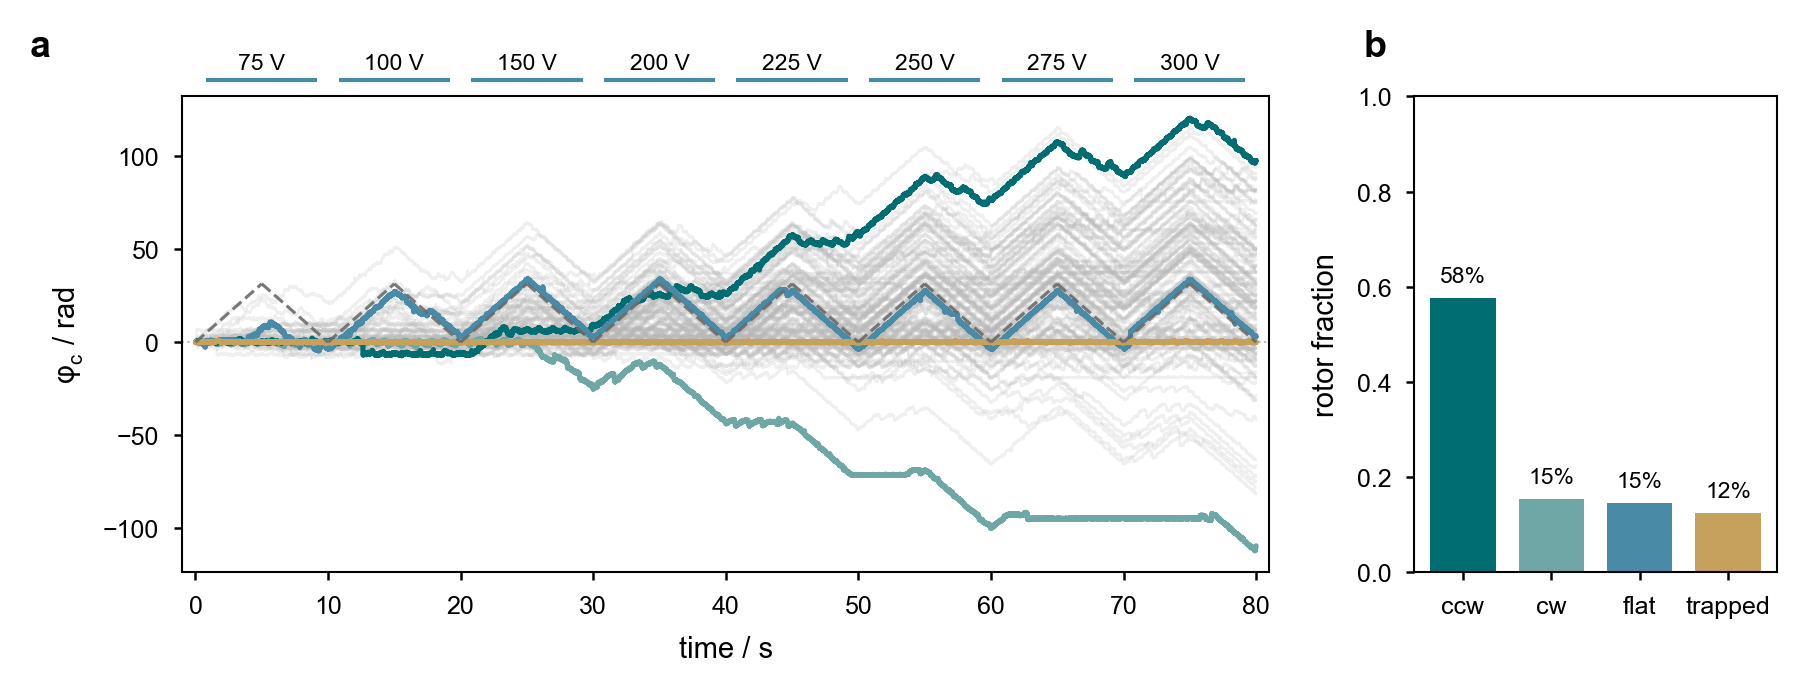

In [16]:
plot_ccw_two_panel_figure(
    m_list,
    variant=None,
    example_ccw=None,
    example_cw=None,
    example_flat=None,
    example_trapped=None,
    ccw_colors=("#006D73",),
    cw_color=CK_colors["target_teal"],
    flat_color=CK_colors["lightblue"],
    trapped_color=CK_colors["warmgold"],
    ensemble_gray=CK_colors["lightgrey"],
    ensemble_alpha=0.22,
    ensemble_lw=0.55,
    example_lw=1.25,
    voltage_label_fontsize=5.5,
    percentage_label_fontsize=5.5,
    reference_freq_hz=1.0,
    reference_color="0.42",
    reference_lw=0.75,
    reference_alpha=0.90,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,
    axes_box=True,
    axes_box_color="black",
    axes_box_lw=0.5,
    axis_label_color="black",
    tick_label_color="black",
    voltage_label_color="black",
    percentage_label_color="black",
    panel_label_color="black",
    panel_widths=(3, 1),
    column_gap=0.2,
    width_mm=150,
    height_mm=65,
    display_dpi=300,
    save_dir=r"R:\_06__Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_4",
    prefix="SI_toFig4_rotating_field_summary",
)

In [52]:
# =============================================================================
# CCW TRANSPORT FIGURE WITH INSET FRACTIONS — UMBRELLA-PAPER STYLE
#
# a | trajectories
#       - all rotors transparent light gray
#       - 1 CCW rotor with maximum positive advancement
#       - 1 exemplary CW rotor in light green
#       - 1 exemplary flat rotor in blue
#       - 1 exemplary trapped rotor in warm gold
#       - dashed ±1 Hz reference trajectory from protocol
#
# inset | rotor-class fractions inside trajectory panel
#
# Only trajectories and class fractions are computed; no activity DataFrames.
#
# Uses existing helpers from your analysis:
#   _classify_subsets_one_m
#   _traj_unwrapped
#   _interp
#   _get2
#   _style_ax
#   PAPER_RC
#   TWO_PI
# =============================================================================

import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path


# =============================================================================
# DEFAULT COLORS
# =============================================================================

CK_colors = {
    "orange": (215/255, 131/255, 41/255),
    "beige": (225/255, 209/255, 180/255),
    "gold": (226/255, 172/255, 72/255),
    "olive": (140/255, 135/255, 59/255),
    "offwhite": (222/255, 224/255, 213/255),
    "palecyan": (167/255, 197/255, 197/255),
    "darkcyan": (105/255, 155/255, 155/255),
    "lightblue": (73/255, 139/255, 167/255),
    "darkblue": (46/255, 89/255, 108/255),
    "darkred": (102/255, 27/255, 35/255),
    "grey": (0.25, 0.25, 0.25),
    "midgrey": (0.45, 0.45, 0.45),
    "lightgrey": (0.72, 0.72, 0.72),
    "black": (0, 0, 0),
    "white": (1, 1, 1),
    "warmgold": (198/255, 161/255, 91/255),
    "target_teal": (111/255, 166/255, 166/255),
    "free_grey": (201/255, 201/255, 201/255),
    "fit_darkgrey": (46/255, 46/255, 46/255),
}
CCW_COLORS = (CK_colors["darkcyan"],)
CW_COLOR = CK_colors["target_teal"]
FLAT_COLOR = CK_colors["lightblue"]
TRAPPED_COLOR = CK_colors["warmgold"]
ENSEMBLE_GRAY = CK_colors["lightgrey"]

# Manuscript typography: override values here if PAPER_RC uses different sizes.
FIGURE_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "mathtext.fontset": "dejavusans",
    "mathtext.default": "regular",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 150,
    "savefig.dpi": 300,
}



# =============================================================================
# SMALL HELPERS
# =============================================================================

def _cwccw_windows(proto):
    """Return alternating CW/CCW protocol windows as (t0, t1, direction)."""
    wins = []

    for key, value in getattr(proto, "items", lambda: [])():
        if not (isinstance(value, (list, tuple)) and len(value) >= 2):
            continue

        s = str(key).lower()

        if "both" in s:
            continue

        if "ccw" in s:
            wins.append((float(value[0]), float(value[1]), +1.0))
        elif "cw" in s:
            wins.append((float(value[0]), float(value[1]), -1.0))

    wins.sort(key=lambda z: z[0])
    return wins


def _voltage_windows(proto):
    """Return one combined interval for every V-ccw/V-cw pair."""
    by_voltage = {}

    for key, w in getattr(proto, "items", lambda: [])():
        m = re.match(r"^\s*(\d+)\s*V-(cw|ccw)\s*$", str(key), flags=re.IGNORECASE)

        if m is None or not (isinstance(w, (list, tuple)) and len(w) >= 2):
            continue

        V = int(m.group(1))
        by_voltage.setdefault(V, []).append((float(w[0]), float(w[1])))

    out = []

    for V, segs in by_voltage.items():
        t0 = min(x[0] for x in segs)
        t1 = max(x[1] for x in segs)
        out.append((t0, t1, V))

    return sorted(out, key=lambda z: z[0])


def _extract_classified_data_one_m(
    m,
    *,
    m_index,
    reference_freq_hz=1.0,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,
):
    """Classify one measurement and extract trajectories + directional response."""

    proto = getattr(m, "protocol", {})
    rb = _get2(proto.get("rot-both", None))

    subsets = _classify_subsets_one_m(
        m,
        reference_freq_hz,
        span_thresh=span_thresh,
        final_abs_min_rad=final_abs_min_rad,
        final_use_relative=final_use_relative,
    )

    trajectories = []

    if rb is not None:
        t0, t1 = rb

        for rotor_class in ("cw", "ccw", "flat", "trapped"):
            for pid in subsets.get(rotor_class, pd.Index([])):
                t, yu = _traj_unwrapped(m, int(pid))

                if t is None:
                    continue

                a, b = max(t0, t[0]), min(t1, t[-1])

                if b <= a:
                    continue

                ya = _interp(t, yu, a)
                mask = (t >= a) & (t <= b)

                if np.count_nonzero(mask) >= 2:
                    tr = np.asarray(t[mask] - t0, float)
                    yr = np.asarray(yu[mask] - ya, float)
                else:
                    yb = _interp(t, yu, b)
                    tr = np.asarray([0.0, b-a], float)
                    yr = np.asarray([0.0, yb-ya], float)

                # Directional displacement within the driven protocol windows.
                # Use the original unwrapped trajectory, not its net endpoint.
                ccw_forward = 0.0
                cw_backward = 0.0
                for w0, w1, direction in _cwccw_windows(proto):
                    wa, wb = max(w0, t[0]), min(w1, t[-1])
                    if wb <= wa:
                        continue
                    delta = float(_interp(t, yu, wb) - _interp(t, yu, wa))
                    if direction > 0:
                        ccw_forward += delta
                    else:
                        cw_backward -= delta

                trajectories.append({
                    "ccw_forward": ccw_forward,
                    "cw_backward": cw_backward,
                    "angular_span": float(np.ptp(yr)),
                    "m_index": int(m_index),
                    "pid": int(pid),
                    "class": rotor_class,
                    "t": tr,
                    "phi": yr,
                    "advancement": float(yr[-1] - yr[0]),
                })

    return subsets, trajectories


# =============================================================================
# DASHED REFERENCE TRACK
# =============================================================================

def _plot_reference_track(
    ax,
    *,
    protocol,
    phi0=0.0,
    origin_s=None,
    freq_hz=1.0,
    color="0.42",
    lw=0.75,
    alpha=0.90,
):
    """Continuous dashed ±1 Hz reference following the actual protocol."""

    wins = _cwccw_windows(protocol)

    if not wins:
        return

    if origin_s is None:
        origin_s = wins[0][0]

    omega = TWO_PI * float(freq_hz)
    phi = float(phi0)

    for t0, t1, direction in wins:
        if t1 <= t0:
            continue

        x0 = t0 - origin_s
        x1 = t1 - origin_s
        phi_next = phi + direction*omega*(t1-t0)

        ax.plot(
            [x0, x1],
            [phi, phi_next],
            ls="--",
            color=color,
            lw=lw,
            alpha=alpha,
            zorder=6,  # Reference above all trajectories
        )

        phi = phi_next


# =============================================================================
# MAIN FIGURE
# =============================================================================

def plot_ccw_two_panel_figure(
    m_list,
    *,
    variant=None,

    # Highlighted examples
    example_ccw=None,
    example_cw=None,
    example_flat=None,
    example_trapped=None,

    # Colors
    ccw_colors=CCW_COLORS,
    cw_color=CW_COLOR,
    flat_color=FLAT_COLOR,
    trapped_color=TRAPPED_COLOR,
    ensemble_gray=ENSEMBLE_GRAY,

    # Classification
    reference_freq_hz=1.0,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,

    # Panel a
    ensemble_alpha=0.22,
    ensemble_lw=0.55,
    example_lw=1.25,
    voltage_label_fontsize=5.5,
    percentage_label_fontsize=5.5,
    reference_color="0.42",
    reference_lw=0.75,
    reference_alpha=0.90,
    show_voltage_labels=True,

    # Boxed axes and typography
    axes_box=True,
    axes_box_color="black",
    axes_box_lw=0.5,
    axis_label_color="black",
    tick_label_color="black",
    voltage_label_color="black",
    percentage_label_color="black",
    panel_label_color="black",

    # Layout
    inset_bounds=(0.045, 0.065, 0.38, 0.30),
    inset_bar_width=0.48,
    inset_background="white",
    inset_alpha=0.94,
    width_mm=120,
    height_mm=74,
    left=0.12,
    right=0.98,
    bottom=0.17,
    top=0.83,
    display_dpi=300,

    # Save
    save_dir=None,
    prefix="Fig_CCW_transport",
):
    """Original trajectory figure with class fractions embedded as an inset."""

    if len(inset_bounds) != 4:
        raise ValueError("inset_bounds must be (left, bottom, width, height).")

    # -------------------------------------------------------------------------
    # Variant
    # -------------------------------------------------------------------------

    available_variants = list(dict.fromkeys(
        str(getattr(m, "variant", "unknown")) for m in m_list
    ))

    if variant is None:
        if len(available_variants) != 1:
            raise ValueError(
                "Several variants are present. Set variant=... explicitly.\n"
                f"Available variants: {available_variants}"
            )

        variant = available_variants[0]

    selected_ms = [
        (mi, m) for mi, m in enumerate(m_list)
        if str(getattr(m, "variant", "unknown")) == str(variant)
    ]

    if not selected_ms:
        raise ValueError(f"No measurements found for variant={variant!r}.")

    # -------------------------------------------------------------------------
    # Extract
    # -------------------------------------------------------------------------

    total_counts = {"cw": 0, "ccw": 0, "flat": 0, "trapped": 0}
    trajectories = []

    for mi, m in selected_ms:
        subsets, segs = _extract_classified_data_one_m(
            m,
            m_index=mi,
            reference_freq_hz=reference_freq_hz,
            span_thresh=span_thresh,
            final_abs_min_rad=final_abs_min_rad,
            final_use_relative=final_use_relative,
        )

        for cls in total_counts:
            total_counts[cls] += int(len(subsets.get(cls, [])))

        trajectories.extend(segs)

    # -------------------------------------------------------------------------
    # Highlights
    # -------------------------------------------------------------------------

    # Best examples by class-specific behavior (not median net advancement):
    # CCW: largest positive net displacement
    # CW:  largest negative net displacement
    # flat: strongest motion in BOTH commanded directions
    # trapped: smallest angular excursion
    def _best_example(rotor_class, score, explicit=None, reverse=True):
        available = [tr for tr in trajectories if tr["class"] == rotor_class]
        if not available:
            raise ValueError(f"No trajectories classified as {rotor_class!r}.")
        if explicit is not None:
            if isinstance(explicit, (tuple, list)) and len(explicit) == 1:
                explicit = explicit[0]
            if isinstance(explicit, (tuple, list)) and len(explicit) == 2:
                key = (int(explicit[0]), int(explicit[1]))
                if key not in [(tr["m_index"], tr["pid"]) for tr in available]:
                    raise ValueError(f"Selected {rotor_class} rotor {key} not found in that class.")
                return key
            matches = [tr for tr in available if tr["pid"] == int(explicit)]
            if len(matches) != 1:
                raise ValueError(f"Specify {rotor_class} rotor as (m_index, pid).")
            return (matches[0]["m_index"], matches[0]["pid"])
        chosen = sorted(available, key=lambda tr: (score(tr), -tr["m_index"], -tr["pid"]), reverse=reverse)[0]
        return (chosen["m_index"], chosen["pid"])

    selected_ccw = [_best_example("ccw", lambda tr: tr["advancement"], example_ccw)]
    selected_cw = _best_example("cw", lambda tr: -tr["advancement"], example_cw)
    selected_flat = _best_example(
        "flat", lambda tr: min(tr["ccw_forward"], tr["cw_backward"]), example_flat
    )
    selected_trapped = _best_example(
        "trapped", lambda tr: tr["angular_span"], example_trapped, reverse=False
    )

    highlight_colors = {
        selected_ccw[0]: ccw_colors[0],
        selected_cw: cw_color,
        selected_flat: flat_color,
        selected_trapped: trapped_color,
    }

    # -------------------------------------------------------------------------
    # Protocol timing
    # -------------------------------------------------------------------------

    protocol0 = getattr(selected_ms[0][1], "protocol", {})
    rb0 = _get2(protocol0.get("rot-both", None))

    if rb0 is not None:
        trajectory_origin = float(rb0[0])
    else:
        wins0 = _cwccw_windows(protocol0)
        trajectory_origin = wins0[0][0] if wins0 else 0.0

    # =========================================================================
    # FIGURE
    # =========================================================================

    mm2in = 1/25.4

    with mpl.rc_context({**globals().get("PAPER_RC", {}), **FIGURE_RC}):

        fig, axA = plt.subplots(figsize=(width_mm*mm2in, height_mm*mm2in), dpi=display_dpi)
        fig.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
        _style_ax(axA)
        for spine in axA.spines.values():
            spine.set_visible(axes_box)
            spine.set_color(axes_box_color)
            spine.set_linewidth(axes_box_lw)
        axA.tick_params(axis="both", which="both", color=axes_box_color, labelcolor=tick_label_color)
        axA.xaxis.label.set_color(axis_label_color)
        axA.yaxis.label.set_color(axis_label_color)

        # =====================================================================
        # a) TRAJECTORIES
        # =====================================================================

        # Plot each trajectory exactly once. Highlighted rotors do not
        # receive an additional gray ensemble trace underneath.
        for tr in trajectories:
            key = (tr["m_index"], tr["pid"])
            highlighted = key in highlight_colors
            axA.plot(
                tr["t"],
                tr["phi"],
                color=highlight_colors[key] if highlighted else ensemble_gray,
                alpha=1.0 if highlighted else ensemble_alpha,
                lw=example_lw if highlighted else ensemble_lw,
                solid_capstyle="round",
                zorder=4 if highlighted else 1,
                rasterized=not highlighted,
            )

        _plot_reference_track(
            axA,
            protocol=protocol0,
            phi0=0.0,
            origin_s=trajectory_origin,
            freq_hz=reference_freq_hz,
            color=reference_color,
            lw=reference_lw,
            alpha=reference_alpha,
        )

        axA.axhline(0, color="0.72", lw=0.5, ls=":", zorder=0)
        axA.set_xlabel("time / s")
        axA.set_ylabel(r"$\varphi_c$ / rad")

        # Voltage bars above trajectory panel
        if show_voltage_labels:
            vwins = _voltage_windows(protocol0)

            if vwins:
                trans = mpl.transforms.blended_transform_factory(axA.transData, axA.transAxes)
                ybar = 1.035

                for t0, t1, V in vwins:
                    x0 = t0 - trajectory_origin
                    x1 = t1 - trajectory_origin
                    dx = x1-x0

                    axA.plot(
                        [x0+0.08*dx, x1-0.08*dx],
                        [ybar, ybar],
                        transform=trans,
                        color=flat_color,
                        lw=1.0,
                        solid_capstyle="butt",
                        clip_on=False,
                    )

                    axA.text(
                        0.5*(x0+x1),
                        ybar+0.015,
                        f"{V} V",
                        transform=trans,
                        ha="center",
                        va="bottom",
                        fontsize=voltage_label_fontsize,
                        color=voltage_label_color,
                        clip_on=False,
                    )
        axA.set_xlim(-1, 81)

        # =====================================================================
        # INSET: CLASS FRACTIONS (INSIDE ORIGINAL TRAJECTORY AXES)
        # =====================================================================
        cats = ["ccw", "cw", "flat", "trapped"]
        raw = np.asarray([total_counts[c] for c in cats], float)
        fracs = raw/max(1.0, raw.sum())
        axInset = axA.inset_axes(inset_bounds, zorder=10)
        axInset.set_facecolor(inset_background)
        axInset.patch.set_alpha(inset_alpha)
        for spine in axInset.spines.values(): spine.set_visible(False)
        x = np.arange(len(cats))
        axInset.bar(x, fracs, color=[ccw_colors[-1], cw_color, flat_color, trapped_color], width=inset_bar_width, edgecolor="none")
        axInset.set_ylim(0, max(0.75, 1.20*float(np.max(fracs))))
        axInset.set_xlim(-0.55, 3.55)
        axInset.set_xticks(x)
        axInset.set_xticklabels(cats, fontsize=5.0)
        axInset.set_yticks([])
        axInset.tick_params(axis="x", length=0, pad=1)
        for xi, frac in enumerate(fracs):
            axInset.text(xi, frac+0.035, f"{100*frac:.0f}%", ha="center", va="bottom", fontsize=5.2)
        axInset.text(0, 1.03, "rotor fractions", transform=axInset.transAxes, ha="left", va="bottom", fontsize=5.8, clip_on=False)

        axA.text(-0.14, 1.07, "a", transform=axA.transAxes, ha="left", va="bottom", fontsize=9,
                 fontweight="bold", color=panel_label_color, clip_on=False)

        # =====================================================================
        # SUMMARY
        # =====================================================================

        print(f"variant      : {variant}")
        print(f"measurements : {len(selected_ms)}")
        print(f"total rotors : {int(raw.sum())}")
        print(f"cw           : {total_counts['cw']}")
        print(f"ccw          : {total_counts['ccw']}")
        print(f"flat         : {total_counts['flat']}")
        print(f"trapped      : {total_counts['trapped']}")
        print()

        print("highlighted CCW:")
        for i, key in enumerate(selected_ccw, 1):
            tr = next(tr for tr in trajectories if (tr["m_index"], tr["pid"]) == key)
            print(f"  {i}: m={key[0]}, pid={key[1]}, advance={tr['advancement']:.2f} rad")

        print(f"highlighted CW      : {selected_cw}")
        print(f"highlighted flat    : {selected_flat}")
        print(f"highlighted trapped : {selected_trapped}")

        # =====================================================================
        # SAVE
        # =====================================================================

        if save_dir is not None:
            save_dir = Path(save_dir)
            save_dir.mkdir(parents=True, exist_ok=True)
            stem = f"{prefix}_inset_v12"

            fig.savefig(save_dir / f"{stem}.png", dpi=350, bbox_inches="tight")
            fig.savefig(save_dir / f"{stem}.svg", bbox_inches="tight")

        plt.show()
        # Keep figure open for Spyder inspection.

# Example call (run after your measurement objects and shared helpers are defined):
# plot_ccw_two_panel_figure(m_list, variant=None, inset_bounds=(0.045, 0.065, 0.38, 0.30),
#                           inset_bar_width=0.48, width_mm=120, height_mm=74,
#                           save_dir=save_dir, prefix="Fig_CCW_transport_outer")


variant      : unknown
measurements : 1
total rotors : 137
cw           : 21
ccw          : 79
flat         : 20
trapped      : 17

highlighted CCW:
  1: m=0, pid=134, advance=97.66 rad
highlighted CW      : (0, 96)
highlighted flat    : (0, 152)
highlighted trapped : (0, 138)


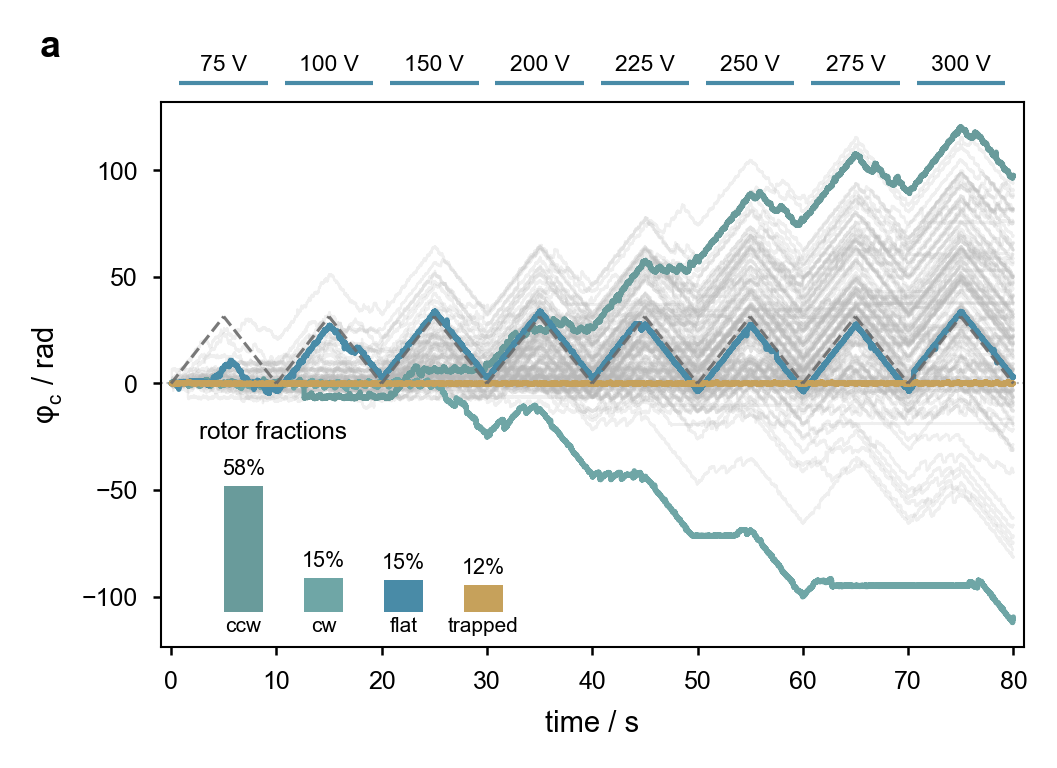

In [55]:
plot_ccw_two_panel_figure(
    m_list,
    variant=None,
    reference_freq_hz=1.0,
    inset_bounds=(0.045, 0.065, 0.38, 0.30),
    inset_bar_width=0.48,
    width_mm=85,
    height_mm=70,
    save_dir=None,
    prefix="Fig_CCW_transport_outer",
)

variant      : unknown
measurements : 1
total rotors : 137
cw           : 21
ccw          : 79
flat         : 20
trapped      : 17

highlighted CCW:
  1: m=0, pid=134, advance=97.66 rad
highlighted CW      : (0, 96)
highlighted flat    : (0, 152)
highlighted trapped : (0, 138)


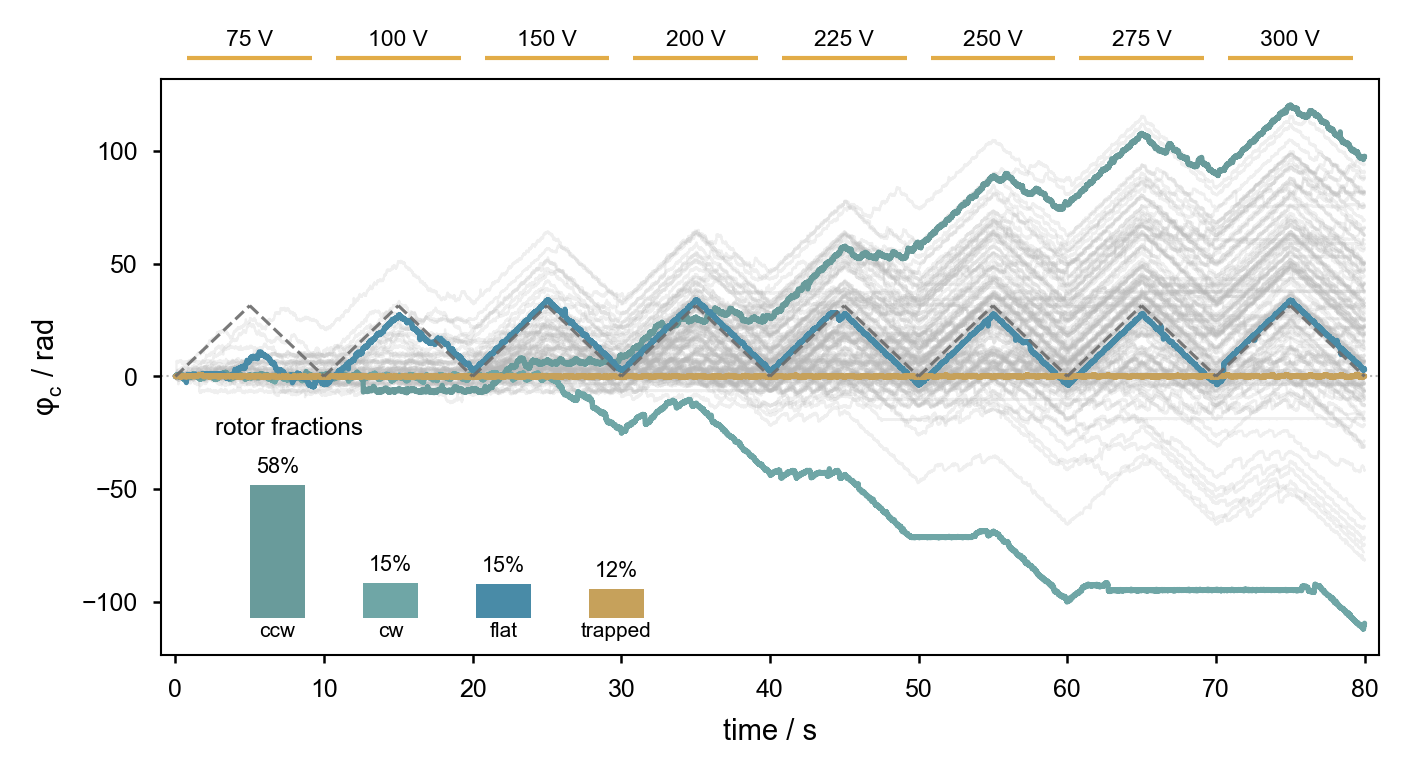

In [57]:
# =============================================================================
# CCW TRANSPORT FIGURE WITH INSET FRACTIONS — UMBRELLA-PAPER STYLE
#
# a | trajectories
#       - all rotors transparent light gray
#       - 1 CCW rotor with maximum positive advancement
#       - 1 exemplary CW rotor in light green
#       - 1 exemplary flat rotor in blue
#       - 1 exemplary trapped rotor in warm gold
#       - dashed ±1 Hz reference trajectory from protocol
#
# inset | rotor-class fractions inside trajectory panel
#
# Only trajectories and class fractions are computed; no activity DataFrames.
#
# Uses existing helpers from your analysis:
#   _classify_subsets_one_m
#   _traj_unwrapped
#   _interp
#   _get2
#   _style_ax
#   PAPER_RC
#   TWO_PI
# =============================================================================

import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path


# =============================================================================
# DEFAULT COLORS
# =============================================================================

CK_colors = {
    "orange": (215/255, 131/255, 41/255),
    "beige": (225/255, 209/255, 180/255),
    "gold": (226/255, 172/255, 72/255),
    "olive": (140/255, 135/255, 59/255),
    "offwhite": (222/255, 224/255, 213/255),
    "palecyan": (167/255, 197/255, 197/255),
    "darkcyan": (105/255, 155/255, 155/255),
    "lightblue": (73/255, 139/255, 167/255),
    "darkblue": (46/255, 89/255, 108/255),
    "darkred": (102/255, 27/255, 35/255),
    "grey": (0.25, 0.25, 0.25),
    "midgrey": (0.45, 0.45, 0.45),
    "lightgrey": (0.72, 0.72, 0.72),
    "black": (0, 0, 0),
    "white": (1, 1, 1),
    "warmgold": (198/255, 161/255, 91/255),
    "target_teal": (111/255, 166/255, 166/255),
    "free_grey": (201/255, 201/255, 201/255),
    "fit_darkgrey": (46/255, 46/255, 46/255),
}
CCW_COLORS = (CK_colors["darkcyan"],)
CW_COLOR = CK_colors["target_teal"]
FLAT_COLOR = CK_colors["lightblue"]
TRAPPED_COLOR = CK_colors["warmgold"]
ENSEMBLE_GRAY = CK_colors["lightgrey"]

# Manuscript typography: override values here if PAPER_RC uses different sizes.
FIGURE_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "mathtext.fontset": "dejavusans",
    "mathtext.default": "regular",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 150,
    "savefig.dpi": 300,
}



# =============================================================================
# SMALL HELPERS
# =============================================================================

def _cwccw_windows(proto):
    """Return alternating CW/CCW protocol windows as (t0, t1, direction)."""
    wins = []

    for key, value in getattr(proto, "items", lambda: [])():
        if not (isinstance(value, (list, tuple)) and len(value) >= 2):
            continue

        s = str(key).lower()

        if "both" in s:
            continue

        if "ccw" in s:
            wins.append((float(value[0]), float(value[1]), +1.0))
        elif "cw" in s:
            wins.append((float(value[0]), float(value[1]), -1.0))

    wins.sort(key=lambda z: z[0])
    return wins


def _voltage_windows(proto):
    """Return one combined interval for every V-ccw/V-cw pair."""
    by_voltage = {}

    for key, w in getattr(proto, "items", lambda: [])():
        m = re.match(r"^\s*(\d+)\s*V-(cw|ccw)\s*$", str(key), flags=re.IGNORECASE)

        if m is None or not (isinstance(w, (list, tuple)) and len(w) >= 2):
            continue

        V = int(m.group(1))
        by_voltage.setdefault(V, []).append((float(w[0]), float(w[1])))

    out = []

    for V, segs in by_voltage.items():
        t0 = min(x[0] for x in segs)
        t1 = max(x[1] for x in segs)
        out.append((t0, t1, V))

    return sorted(out, key=lambda z: z[0])


def _extract_classified_data_one_m(
    m,
    *,
    m_index,
    reference_freq_hz=1.0,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,
):
    """Classify one measurement and extract trajectories + directional response."""

    proto = getattr(m, "protocol", {})
    rb = _get2(proto.get("rot-both", None))

    subsets = _classify_subsets_one_m(
        m,
        reference_freq_hz,
        span_thresh=span_thresh,
        final_abs_min_rad=final_abs_min_rad,
        final_use_relative=final_use_relative,
    )

    trajectories = []

    if rb is not None:
        t0, t1 = rb

        for rotor_class in ("cw", "ccw", "flat", "trapped"):
            for pid in subsets.get(rotor_class, pd.Index([])):
                t, yu = _traj_unwrapped(m, int(pid))

                if t is None:
                    continue

                a, b = max(t0, t[0]), min(t1, t[-1])

                if b <= a:
                    continue

                ya = _interp(t, yu, a)
                mask = (t >= a) & (t <= b)

                if np.count_nonzero(mask) >= 2:
                    tr = np.asarray(t[mask] - t0, float)
                    yr = np.asarray(yu[mask] - ya, float)
                else:
                    yb = _interp(t, yu, b)
                    tr = np.asarray([0.0, b-a], float)
                    yr = np.asarray([0.0, yb-ya], float)

                # Directional displacement within the driven protocol windows.
                # Use the original unwrapped trajectory, not its net endpoint.
                ccw_forward = 0.0
                cw_backward = 0.0
                for w0, w1, direction in _cwccw_windows(proto):
                    wa, wb = max(w0, t[0]), min(w1, t[-1])
                    if wb <= wa:
                        continue
                    delta = float(_interp(t, yu, wb) - _interp(t, yu, wa))
                    if direction > 0:
                        ccw_forward += delta
                    else:
                        cw_backward -= delta

                trajectories.append({
                    "ccw_forward": ccw_forward,
                    "cw_backward": cw_backward,
                    "angular_span": float(np.ptp(yr)),
                    "m_index": int(m_index),
                    "pid": int(pid),
                    "class": rotor_class,
                    "t": tr,
                    "phi": yr,
                    "advancement": float(yr[-1] - yr[0]),
                })

    return subsets, trajectories


# =============================================================================
# DASHED REFERENCE TRACK
# =============================================================================

def _plot_reference_track(
    ax,
    *,
    protocol,
    phi0=0.0,
    origin_s=None,
    freq_hz=1.0,
    color="0.42",
    lw=0.75,
    alpha=0.90,
):
    """Continuous dashed ±1 Hz reference following the actual protocol."""

    wins = _cwccw_windows(protocol)

    if not wins:
        return

    if origin_s is None:
        origin_s = wins[0][0]

    omega = TWO_PI * float(freq_hz)
    phi = float(phi0)

    for t0, t1, direction in wins:
        if t1 <= t0:
            continue

        x0 = t0 - origin_s
        x1 = t1 - origin_s
        phi_next = phi + direction*omega*(t1-t0)

        ax.plot(
            [x0, x1],
            [phi, phi_next],
            ls="--",
            color=color,
            lw=lw,
            alpha=alpha,
            zorder=6,  # Reference above all trajectories
        )

        phi = phi_next


# =============================================================================
# MAIN FIGURE
# =============================================================================

def plot_ccw_two_panel_figure(
    m_list,
    *,
    variant=None,

    # Highlighted examples
    example_ccw=None,
    example_cw=None,
    example_flat=None,
    example_trapped=None,

    # Colors
    ccw_colors=CCW_COLORS,
    cw_color=CW_COLOR,
    flat_color=FLAT_COLOR,
    trapped_color=TRAPPED_COLOR,
    ensemble_gray=ENSEMBLE_GRAY,

    # Classification
    reference_freq_hz=1.0,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,

    # Panel a
    ensemble_alpha=0.22,
    ensemble_lw=0.55,
    example_lw=1.25,
    voltage_label_fontsize=5.5,
    percentage_label_fontsize=5.5,
    reference_color="0.42",
    reference_lw=0.75,
    reference_alpha=0.90,
    show_voltage_labels=True,

    # Boxed axes and typography
    axes_box=True,
    axes_box_color="black",
    axes_box_lw=0.5,
    axis_label_color="black",
    tick_label_color="black",
    voltage_label_color="black",
    percentage_label_color="black",
    panel_label_color="black",

    # Layout
    inset_bounds=(0.045, 0.065, 0.38, 0.30),
    inset_bar_width=0.48,
    inset_background="white",
    inset_alpha=0.94,
    width_mm=120,
    height_mm=74,
    left=0.12,
    right=0.98,
    bottom=0.17,
    top=0.83,
    display_dpi=300,

    # Save
    save_dir=None,
    prefix="Fig_CCW_transport",
):
    """Original trajectory figure with class fractions embedded as an inset."""

    if len(inset_bounds) != 4:
        raise ValueError("inset_bounds must be (left, bottom, width, height).")

    # -------------------------------------------------------------------------
    # Variant
    # -------------------------------------------------------------------------

    available_variants = list(dict.fromkeys(
        str(getattr(m, "variant", "unknown")) for m in m_list
    ))

    if variant is None:
        if len(available_variants) != 1:
            raise ValueError(
                "Several variants are present. Set variant=... explicitly.\n"
                f"Available variants: {available_variants}"
            )

        variant = available_variants[0]

    selected_ms = [
        (mi, m) for mi, m in enumerate(m_list)
        if str(getattr(m, "variant", "unknown")) == str(variant)
    ]

    if not selected_ms:
        raise ValueError(f"No measurements found for variant={variant!r}.")

    # -------------------------------------------------------------------------
    # Extract
    # -------------------------------------------------------------------------

    total_counts = {"cw": 0, "ccw": 0, "flat": 0, "trapped": 0}
    trajectories = []

    for mi, m in selected_ms:
        subsets, segs = _extract_classified_data_one_m(
            m,
            m_index=mi,
            reference_freq_hz=reference_freq_hz,
            span_thresh=span_thresh,
            final_abs_min_rad=final_abs_min_rad,
            final_use_relative=final_use_relative,
        )

        for cls in total_counts:
            total_counts[cls] += int(len(subsets.get(cls, [])))

        trajectories.extend(segs)

    # -------------------------------------------------------------------------
    # Highlights
    # -------------------------------------------------------------------------

    # Best examples by class-specific behavior (not median net advancement):
    # CCW: largest positive net displacement
    # CW:  largest negative net displacement
    # flat: strongest motion in BOTH commanded directions
    # trapped: smallest angular excursion
    def _best_example(rotor_class, score, explicit=None, reverse=True):
        available = [tr for tr in trajectories if tr["class"] == rotor_class]
        if not available:
            raise ValueError(f"No trajectories classified as {rotor_class!r}.")
        if explicit is not None:
            if isinstance(explicit, (tuple, list)) and len(explicit) == 1:
                explicit = explicit[0]
            if isinstance(explicit, (tuple, list)) and len(explicit) == 2:
                key = (int(explicit[0]), int(explicit[1]))
                if key not in [(tr["m_index"], tr["pid"]) for tr in available]:
                    raise ValueError(f"Selected {rotor_class} rotor {key} not found in that class.")
                return key
            matches = [tr for tr in available if tr["pid"] == int(explicit)]
            if len(matches) != 1:
                raise ValueError(f"Specify {rotor_class} rotor as (m_index, pid).")
            return (matches[0]["m_index"], matches[0]["pid"])
        chosen = sorted(available, key=lambda tr: (score(tr), -tr["m_index"], -tr["pid"]), reverse=reverse)[0]
        return (chosen["m_index"], chosen["pid"])

    selected_ccw = [_best_example("ccw", lambda tr: tr["advancement"], example_ccw)]
    selected_cw = _best_example("cw", lambda tr: -tr["advancement"], example_cw)
    selected_flat = _best_example(
        "flat", lambda tr: min(tr["ccw_forward"], tr["cw_backward"]), example_flat
    )
    selected_trapped = _best_example(
        "trapped", lambda tr: tr["angular_span"], example_trapped, reverse=False
    )

    highlight_colors = {
        selected_ccw[0]: ccw_colors[0],
        selected_cw: cw_color,
        selected_flat: flat_color,
        selected_trapped: trapped_color,
    }

    # -------------------------------------------------------------------------
    # Protocol timing
    # -------------------------------------------------------------------------

    protocol0 = getattr(selected_ms[0][1], "protocol", {})
    rb0 = _get2(protocol0.get("rot-both", None))

    if rb0 is not None:
        trajectory_origin = float(rb0[0])
    else:
        wins0 = _cwccw_windows(protocol0)
        trajectory_origin = wins0[0][0] if wins0 else 0.0

    # =========================================================================
    # FIGURE
    # =========================================================================

    mm2in = 1/25.4

    with mpl.rc_context({**globals().get("PAPER_RC", {}), **FIGURE_RC}):

        fig, axA = plt.subplots(figsize=(width_mm*mm2in, height_mm*mm2in), dpi=display_dpi)
        fig.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
        _style_ax(axA)
        for spine in axA.spines.values():
            spine.set_visible(axes_box)
            spine.set_color(axes_box_color)
            spine.set_linewidth(axes_box_lw)
        axA.tick_params(axis="both", which="both", color=axes_box_color, labelcolor=tick_label_color)
        axA.xaxis.label.set_color(axis_label_color)
        axA.yaxis.label.set_color(axis_label_color)

        # =====================================================================
        # a) TRAJECTORIES
        # =====================================================================

        # Plot each trajectory exactly once. Highlighted rotors do not
        # receive an additional gray ensemble trace underneath.
        for tr in trajectories:
            key = (tr["m_index"], tr["pid"])
            highlighted = key in highlight_colors
            axA.plot(
                tr["t"],
                tr["phi"],
                color=highlight_colors[key] if highlighted else ensemble_gray,
                alpha=1.0 if highlighted else ensemble_alpha,
                lw=example_lw if highlighted else ensemble_lw,
                solid_capstyle="round",
                zorder=4 if highlighted else 1,
                rasterized=not highlighted,
            )

        _plot_reference_track(
            axA,
            protocol=protocol0,
            phi0=0.0,
            origin_s=trajectory_origin,
            freq_hz=reference_freq_hz,
            color=reference_color,
            lw=reference_lw,
            alpha=reference_alpha,
        )

        axA.axhline(0, color="0.72", lw=0.5, ls=":", zorder=0)
        axA.set_xlabel("time / s")
        axA.set_ylabel(r"$\varphi_c$ / rad")

        # Voltage bars above trajectory panel
        if show_voltage_labels:
            vwins = _voltage_windows(protocol0)

            if vwins:
                trans = mpl.transforms.blended_transform_factory(axA.transData, axA.transAxes)
                ybar = 1.035

                for t0, t1, V in vwins:
                    x0 = t0 - trajectory_origin
                    x1 = t1 - trajectory_origin
                    dx = x1-x0

                    axA.plot(
                        [x0+0.08*dx, x1-0.08*dx],
                        [ybar, ybar],
                        transform=trans,
                        color=CK_colors["gold"],
                        lw=1.0,
                        solid_capstyle="butt",
                        clip_on=False,
                    )

                    axA.text(
                        0.5*(x0+x1),
                        ybar+0.015,
                        f"{V} V",
                        transform=trans,
                        ha="center",
                        va="bottom",
                        fontsize=voltage_label_fontsize,
                        color=voltage_label_color,
                        clip_on=False,
                    )
        axA.set_xlim(-1, 81)

        # =====================================================================
        # INSET: CLASS FRACTIONS (INSIDE ORIGINAL TRAJECTORY AXES)
        # =====================================================================
        cats = ["ccw", "cw", "flat", "trapped"]
        raw = np.asarray([total_counts[c] for c in cats], float)
        fracs = raw/max(1.0, raw.sum())
        axInset = axA.inset_axes(inset_bounds, zorder=10)
        axInset.set_facecolor(inset_background)
        axInset.patch.set_alpha(inset_alpha)
        for spine in axInset.spines.values(): spine.set_visible(False)
        x = np.arange(len(cats))
        axInset.bar(x, fracs, color=[ccw_colors[-1], cw_color, flat_color, trapped_color], width=inset_bar_width, edgecolor="none")
        axInset.set_ylim(0, max(0.75, 1.20*float(np.max(fracs))))
        axInset.set_xlim(-0.55, 3.55)
        axInset.set_xticks(x)
        axInset.set_xticklabels(cats, fontsize=5.0)
        axInset.set_yticks([])
        axInset.tick_params(axis="x", length=0, pad=1)
        for xi, frac in enumerate(fracs):
            axInset.text(xi, frac+0.035, f"{100*frac:.0f}%", ha="center", va="bottom", fontsize=5.2)
        axInset.text(0, 1.03, "rotor fractions", transform=axInset.transAxes, ha="left", va="bottom", fontsize=5.8, clip_on=False)


        # =====================================================================
        # SUMMARY
        # =====================================================================

        print(f"variant      : {variant}")
        print(f"measurements : {len(selected_ms)}")
        print(f"total rotors : {int(raw.sum())}")
        print(f"cw           : {total_counts['cw']}")
        print(f"ccw          : {total_counts['ccw']}")
        print(f"flat         : {total_counts['flat']}")
        print(f"trapped      : {total_counts['trapped']}")
        print()

        print("highlighted CCW:")
        for i, key in enumerate(selected_ccw, 1):
            tr = next(tr for tr in trajectories if (tr["m_index"], tr["pid"]) == key)
            print(f"  {i}: m={key[0]}, pid={key[1]}, advance={tr['advancement']:.2f} rad")

        print(f"highlighted CW      : {selected_cw}")
        print(f"highlighted flat    : {selected_flat}")
        print(f"highlighted trapped : {selected_trapped}")

        # =====================================================================
        # SAVE
        # =====================================================================

        if save_dir is not None:
            save_dir = Path(save_dir)
            save_dir.mkdir(parents=True, exist_ok=True)
            stem = f"{prefix}_inset_v12"

            fig.savefig(save_dir / f"{stem}.png", dpi=350, bbox_inches="tight")
            fig.savefig(save_dir / f"{stem}.svg", bbox_inches="tight")

        plt.show()
        # Keep figure open for Spyder inspection.


plot_ccw_two_panel_figure(m_list, variant=None, inset_bounds=(0.045, 0.065, 0.38, 0.30),
                          inset_bar_width=0.48, width_mm=120, height_mm=74,
                          save_dir=None, prefix="Fig_CCW_transport_outer")


variant      : unknown
measurements : 1
total rotors : 137
cw           : 21
ccw          : 79
flat         : 20
trapped      : 17

highlighted CCW:
  1: m=0, pid=134, advance=97.66 rad
  2: m=0, pid=211, advance=93.91 rad
  3: m=0, pid=33, advance=90.34 rad
highlighted flat    : (0, 152)
highlighted trapped : (0, 138)


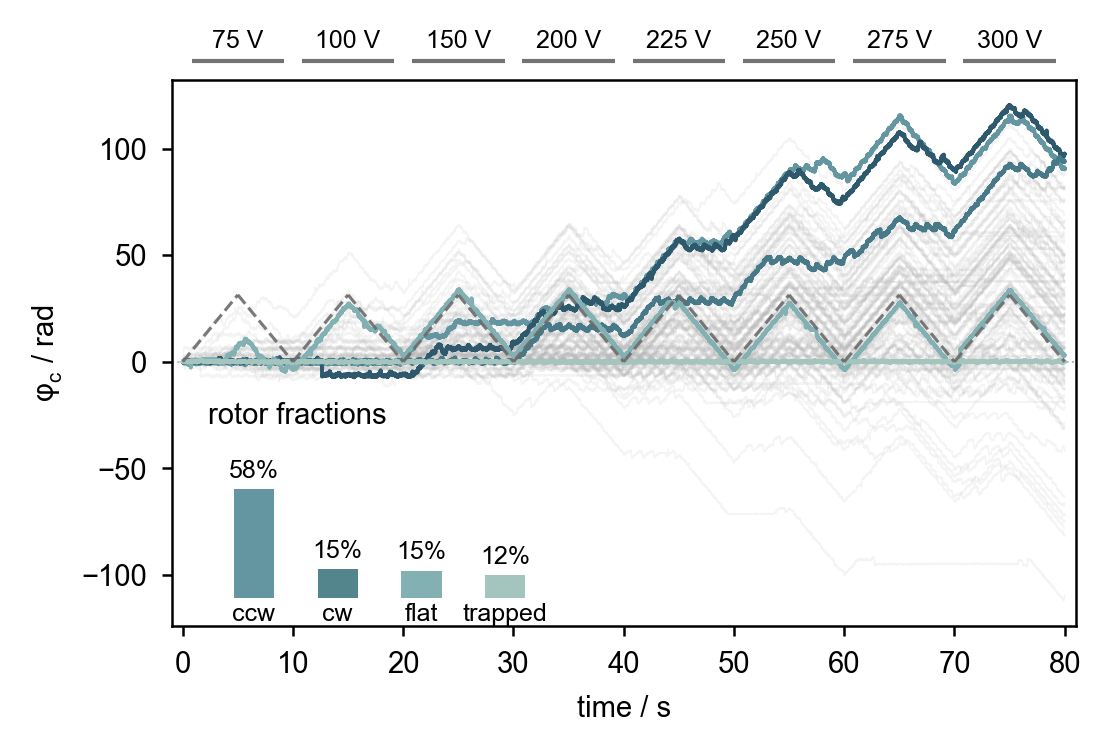

In [71]:
# =============================================================================
# CCW TRANSPORT FIGURE WITH INSET FRACTIONS — UMBRELLA-PAPER STYLE
#
# a | trajectories
#       - all rotors transparent light gray
#       - 1 CCW rotor with maximum positive advancement
#       - 1 exemplary CW rotor in light green
#       - 1 exemplary flat rotor in blue
#       - 1 exemplary trapped rotor in warm gold
#       - dashed ±1 Hz reference trajectory from protocol
#
# inset | rotor-class fractions inside trajectory panel
#
# Only trajectories and class fractions are computed; no activity DataFrames.
#
# Uses existing helpers from your analysis:
#   _classify_subsets_one_m
#   _traj_unwrapped
#   _interp
#   _get2
#   _style_ax
#   PAPER_RC
#   TWO_PI
# =============================================================================

import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path


# =============================================================================
# DEFAULT COLORS
# =============================================================================

CK_colors = {
    "orange": (215/255, 131/255, 41/255),
    "beige": (225/255, 209/255, 180/255),
    "gold": (226/255, 172/255, 72/255),
    "olive": (140/255, 135/255, 59/255),
    "offwhite": (222/255, 224/255, 213/255),
    "palecyan": (167/255, 197/255, 197/255),
    "darkcyan": (105/255, 155/255, 155/255),
    "lightblue": (73/255, 139/255, 167/255),
    "darkblue": (46/255, 89/255, 108/255),
    "darkred": (102/255, 27/255, 35/255),
    "grey": (0.25, 0.25, 0.25),
    "midgrey": (0.45, 0.45, 0.45),
    "lightgrey": (0.72, 0.72, 0.72),
    "black": (0, 0, 0),
    "white": (1, 1, 1),
    "warmgold": (198/255, 161/255, 91/255),
    "target_teal": (111/255, 166/255, 166/255),
    "free_grey": (201/255, 201/255, 201/255),
    "fit_darkgrey": (46/255, 46/255, 46/255),
}
CCW_COLORS = (CK_colors["darkblue"],)
CW_COLOR = "#53858D"
FLAT_COLOR = "#83B0B2"
TRAPPED_COLOR = "#A4C4BE"
ENSEMBLE_GRAY = CK_colors["lightgrey"]

# Manuscript typography: override values here if PAPER_RC uses different sizes.
FIGURE_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "mathtext.fontset": "dejavusans",
    "mathtext.default": "regular",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 150,
    "savefig.dpi": 300,
}



# =============================================================================
# SMALL HELPERS
# =============================================================================

def _cwccw_windows(proto):
    """Return alternating CW/CCW protocol windows as (t0, t1, direction)."""
    wins = []

    for key, value in getattr(proto, "items", lambda: [])():
        if not (isinstance(value, (list, tuple)) and len(value) >= 2):
            continue

        s = str(key).lower()

        if "both" in s:
            continue

        if "ccw" in s:
            wins.append((float(value[0]), float(value[1]), +1.0))
        elif "cw" in s:
            wins.append((float(value[0]), float(value[1]), -1.0))

    wins.sort(key=lambda z: z[0])
    return wins


def _voltage_windows(proto):
    """Return one combined interval for every V-ccw/V-cw pair."""
    by_voltage = {}

    for key, w in getattr(proto, "items", lambda: [])():
        m = re.match(r"^\s*(\d+)\s*V-(cw|ccw)\s*$", str(key), flags=re.IGNORECASE)

        if m is None or not (isinstance(w, (list, tuple)) and len(w) >= 2):
            continue

        V = int(m.group(1))
        by_voltage.setdefault(V, []).append((float(w[0]), float(w[1])))

    out = []

    for V, segs in by_voltage.items():
        t0 = min(x[0] for x in segs)
        t1 = max(x[1] for x in segs)
        out.append((t0, t1, V))

    return sorted(out, key=lambda z: z[0])


def _extract_classified_data_one_m(
    m,
    *,
    m_index,
    reference_freq_hz=1.0,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,
):
    """Classify one measurement and extract trajectories + directional response."""

    proto = getattr(m, "protocol", {})
    rb = _get2(proto.get("rot-both", None))

    subsets = _classify_subsets_one_m(
        m,
        reference_freq_hz,
        span_thresh=span_thresh,
        final_abs_min_rad=final_abs_min_rad,
        final_use_relative=final_use_relative,
    )

    trajectories = []

    if rb is not None:
        t0, t1 = rb

        for rotor_class in ("cw", "ccw", "flat", "trapped"):
            for pid in subsets.get(rotor_class, pd.Index([])):
                t, yu = _traj_unwrapped(m, int(pid))

                if t is None:
                    continue

                a, b = max(t0, t[0]), min(t1, t[-1])

                if b <= a:
                    continue

                ya = _interp(t, yu, a)
                mask = (t >= a) & (t <= b)

                if np.count_nonzero(mask) >= 2:
                    tr = np.asarray(t[mask] - t0, float)
                    yr = np.asarray(yu[mask] - ya, float)
                else:
                    yb = _interp(t, yu, b)
                    tr = np.asarray([0.0, b-a], float)
                    yr = np.asarray([0.0, yb-ya], float)

                # Directional displacement within the driven protocol windows.
                # Use the original unwrapped trajectory, not its net endpoint.
                ccw_forward = 0.0
                cw_backward = 0.0
                for w0, w1, direction in _cwccw_windows(proto):
                    wa, wb = max(w0, t[0]), min(w1, t[-1])
                    if wb <= wa:
                        continue
                    delta = float(_interp(t, yu, wb) - _interp(t, yu, wa))
                    if direction > 0:
                        ccw_forward += delta
                    else:
                        cw_backward -= delta

                trajectories.append({
                    "ccw_forward": ccw_forward,
                    "cw_backward": cw_backward,
                    "angular_span": float(np.ptp(yr)),
                    "m_index": int(m_index),
                    "pid": int(pid),
                    "class": rotor_class,
                    "t": tr,
                    "phi": yr,
                    "advancement": float(yr[-1] - yr[0]),
                })

    return subsets, trajectories


# =============================================================================
# DASHED REFERENCE TRACK
# =============================================================================

def _plot_reference_track(
    ax,
    *,
    protocol,
    phi0=0.0,
    origin_s=None,
    freq_hz=1.0,
    color="0.42",
    lw=0.75,
    alpha=0.90,
):
    """Continuous dashed ±1 Hz reference following the actual protocol."""

    wins = _cwccw_windows(protocol)

    if not wins:
        return

    if origin_s is None:
        origin_s = wins[0][0]

    omega = TWO_PI * float(freq_hz)
    phi = float(phi0)

    for t0, t1, direction in wins:
        if t1 <= t0:
            continue

        x0 = t0 - origin_s
        x1 = t1 - origin_s
        phi_next = phi + direction*omega*(t1-t0)

        ax.plot(
            [x0, x1],
            [phi, phi_next],
            ls="--",
            color=color,
            lw=lw,
            alpha=alpha,
            zorder=6,  # Reference above all trajectories
        )

        phi = phi_next


# =============================================================================
# MAIN FIGURE
# =============================================================================

def plot_ccw_two_panel_figure(
    m_list,
    *,
    variant=None,

    # Highlighted examples
    example_ccw=None,
    example_cw=None,
    example_flat=None,
    example_trapped=None,

    # Colors
    ccw_colors=CCW_COLORS,
    cw_color=CW_COLOR,
    flat_color=FLAT_COLOR,
    trapped_color=TRAPPED_COLOR,
    ensemble_gray=ENSEMBLE_GRAY,

    # Classification
    reference_freq_hz=1.0,
    span_thresh=2*np.pi,
    final_abs_min_rad=3*np.pi,
    final_use_relative=False,

    # Panel a
    ensemble_alpha=0.15,
    ensemble_lw=0.35,
    example_lw=0.95,
    voltage_label_fontsize=6,
    inset_fontsize=6,
    inset_title_fontsize=7,
    voltage_bar_color=CK_colors["midgrey"],
    percentage_label_fontsize=5.5,
    reference_color="0.42",
    reference_lw=0.75,
    reference_alpha=0.90,
    show_voltage_labels=True,

    # Boxed axes and typography
    axes_box=True,
    axes_box_color="black",
    axes_box_lw=0.6,
    axis_label_color="black",
    tick_label_color="black",
    voltage_label_color="black",
    percentage_label_color="black",
    panel_label_color="black",

    # Layout
    inset_bounds=(0.045, 0.065, 0.38, 0.30),
    inset_bar_width=0.48,
    inset_background="white",
    inset_alpha=0.94,
    width_mm=120,
    height_mm=74,
    left=0.12,
    right=0.98,
    bottom=0.17,
    top=0.83,
    display_dpi=300,

    # Save
    save_dir=None,
    prefix="Fig_CCW_transport",
):
    """Original trajectory figure with class fractions embedded as an inset."""

    if len(inset_bounds) != 4:
        raise ValueError("inset_bounds must be (left, bottom, width, height).")

    # -------------------------------------------------------------------------
    # Variant
    # -------------------------------------------------------------------------

    available_variants = list(dict.fromkeys(
        str(getattr(m, "variant", "unknown")) for m in m_list
    ))

    if variant is None:
        if len(available_variants) != 1:
            raise ValueError(
                "Several variants are present. Set variant=... explicitly.\n"
                f"Available variants: {available_variants}"
            )

        variant = available_variants[0]

    selected_ms = [
        (mi, m) for mi, m in enumerate(m_list)
        if str(getattr(m, "variant", "unknown")) == str(variant)
    ]

    if not selected_ms:
        raise ValueError(f"No measurements found for variant={variant!r}.")

    # -------------------------------------------------------------------------
    # Extract
    # -------------------------------------------------------------------------

    total_counts = {"cw": 0, "ccw": 0, "flat": 0, "trapped": 0}
    trajectories = []

    for mi, m in selected_ms:
        subsets, segs = _extract_classified_data_one_m(
            m,
            m_index=mi,
            reference_freq_hz=reference_freq_hz,
            span_thresh=span_thresh,
            final_abs_min_rad=final_abs_min_rad,
            final_use_relative=final_use_relative,
        )

        for cls in total_counts:
            total_counts[cls] += int(len(subsets.get(cls, [])))

        trajectories.extend(segs)

    # -------------------------------------------------------------------------
    # Highlights
    # -------------------------------------------------------------------------

    # Best examples by class-specific behavior (not median net advancement):
    # CCW: largest positive net displacement
    # CW:  largest negative net displacement
    # flat: strongest motion in BOTH commanded directions
    # trapped: smallest angular excursion
    def _best_example(rotor_class, score, explicit=None, reverse=True):
        available = [tr for tr in trajectories if tr["class"] == rotor_class]
        if not available:
            raise ValueError(f"No trajectories classified as {rotor_class!r}.")
        if explicit is not None:
            if isinstance(explicit, (tuple, list)) and len(explicit) == 1:
                explicit = explicit[0]
            if isinstance(explicit, (tuple, list)) and len(explicit) == 2:
                key = (int(explicit[0]), int(explicit[1]))
                if key not in [(tr["m_index"], tr["pid"]) for tr in available]:
                    raise ValueError(f"Selected {rotor_class} rotor {key} not found in that class.")
                return key
            matches = [tr for tr in available if tr["pid"] == int(explicit)]
            if len(matches) != 1:
                raise ValueError(f"Specify {rotor_class} rotor as (m_index, pid).")
            return (matches[0]["m_index"], matches[0]["pid"])
        chosen = sorted(available, key=lambda tr: (score(tr), -tr["m_index"], -tr["pid"]), reverse=reverse)[0]
        return (chosen["m_index"], chosen["pid"])

    # Three distinct CCW rotors: highest net advancement by default.
    # example_ccw may be None, a single rotor ID/(m_index, pid), or a list of three.
    ccw_ranked = sorted((tr for tr in trajectories if tr["class"] == "ccw"), key=lambda tr: tr["advancement"], reverse=True)
    if len(ccw_ranked) < 3:
        raise ValueError(f"Three CCW trajectories required; found {len(ccw_ranked)}.")
    if example_ccw is None:
        selected_ccw = [(tr["m_index"], tr["pid"]) for tr in ccw_ranked[:3]]
    else:
        # A tuple of two integers denotes one (measurement index, particle ID).
        if isinstance(example_ccw, tuple) and len(example_ccw) == 2 and all(isinstance(v, (int, np.integer)) for v in example_ccw):
            requested = [example_ccw]
        elif isinstance(example_ccw, (list, tuple)):
            requested = list(example_ccw)
        else:
            requested = [example_ccw]
        selected_ccw = [_best_example("ccw", lambda tr: tr["advancement"], explicit=v) for v in requested]
        if len(set(selected_ccw)) != len(selected_ccw):
            raise ValueError("example_ccw contains duplicate rotors.")
        selected_ccw += [(tr["m_index"], tr["pid"]) for tr in ccw_ranked if (tr["m_index"], tr["pid"]) not in selected_ccw][:max(0, 3-len(selected_ccw))]
        if len(selected_ccw) != 3:
            raise ValueError("Specify at most three CCW examples.")
    selected_flat = _best_example("flat", lambda tr: min(tr["ccw_forward"], tr["cw_backward"]), example_flat)
    selected_trapped = _best_example("trapped", lambda tr: tr["angular_span"], example_trapped, reverse=False)

    if len(ccw_colors) < 1:
        raise ValueError("ccw_colors must contain at least one color.")
    highlight_colors = {key: ccw_colors[i % len(ccw_colors)] for i, key in enumerate(selected_ccw)}
    highlight_colors.update({selected_flat: flat_color, selected_trapped: trapped_color})

    # -------------------------------------------------------------------------
    # Protocol timing
    # -------------------------------------------------------------------------

    protocol0 = getattr(selected_ms[0][1], "protocol", {})
    rb0 = _get2(protocol0.get("rot-both", None))

    if rb0 is not None:
        trajectory_origin = float(rb0[0])
    else:
        wins0 = _cwccw_windows(protocol0)
        trajectory_origin = wins0[0][0] if wins0 else 0.0

    # =========================================================================
    # FIGURE
    # =========================================================================

    mm2in = 1/25.4

    with mpl.rc_context({**globals().get("PAPER_RC", {}), **FIGURE_RC}):

        fig, axA = plt.subplots(figsize=(width_mm*mm2in, height_mm*mm2in), dpi=display_dpi)
        fig.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
        _style_ax(axA)
        for spine in axA.spines.values():
            spine.set_visible(axes_box)
            spine.set_color(axes_box_color)
            spine.set_linewidth(axes_box_lw)
        axA.tick_params(axis="both", which="both", direction="out", length=2.4, width=0.6, labelsize=7, color=axes_box_color, labelcolor=tick_label_color)
        axA.xaxis.label.set_color(axis_label_color)
        axA.yaxis.label.set_color(axis_label_color)

        # =====================================================================
        # a) TRAJECTORIES
        # =====================================================================

        # Plot each trajectory exactly once. Highlighted rotors do not
        # receive an additional gray ensemble trace underneath.
        for tr in trajectories:
            key = (tr["m_index"], tr["pid"])
            highlighted = key in highlight_colors
            line, = axA.plot(
                tr["t"],
                tr["phi"],
                color=highlight_colors[key] if highlighted else ensemble_gray,
                alpha=1.0 if highlighted else ensemble_alpha,
                lw=example_lw if highlighted else ensemble_lw,
                solid_capstyle="round",
                zorder=4 if highlighted else 1,
                rasterized=False,  # Keep every rotor as an editable vector path
            )
            line.set_gid(f"rotor_m{tr['m_index']}_pid{tr['pid']}_{tr['class']}")

        _plot_reference_track(
            axA,
            protocol=protocol0,
            phi0=0.0,
            origin_s=trajectory_origin,
            freq_hz=reference_freq_hz,
            color=reference_color,
            lw=reference_lw,
            alpha=reference_alpha,
        )

        axA.axhline(0, color="0.72", lw=0.5, ls=":", zorder=0)
        axA.set_xlabel("time / s")
        axA.set_ylabel(r"$\varphi_c$ / rad")

        # Voltage bars above trajectory panel
        if show_voltage_labels:
            vwins = _voltage_windows(protocol0)

            if vwins:
                trans = mpl.transforms.blended_transform_factory(axA.transData, axA.transAxes)
                ybar = 1.035

                for t0, t1, V in vwins:
                    x0 = t0 - trajectory_origin
                    x1 = t1 - trajectory_origin
                    dx = x1-x0

                    axA.plot(
                        [x0+0.08*dx, x1-0.08*dx],
                        [ybar, ybar],
                        transform=trans,
                        color=voltage_bar_color,
                        lw=1.0,
                        solid_capstyle="butt",
                        clip_on=False,
                    )

                    axA.text(
                        0.5*(x0+x1),
                        ybar+0.015,
                        f"{V} V",
                        transform=trans,
                        ha="center",
                        va="bottom",
                        fontsize=voltage_label_fontsize,
                        color=voltage_label_color,
                        clip_on=False,
                    )
        axA.set_xlim(-1, 81)

        # =====================================================================
        # INSET: CLASS FRACTIONS (INSIDE ORIGINAL TRAJECTORY AXES)
        # =====================================================================
        cats = ["ccw", "cw", "flat", "trapped"]
        raw = np.asarray([total_counts[c] for c in cats], float)
        fracs = raw/max(1.0, raw.sum())
        axInset = axA.inset_axes(inset_bounds, zorder=10)
        axInset.set_facecolor(inset_background)
        axInset.patch.set_alpha(inset_alpha)
        for spine in axInset.spines.values(): spine.set_visible(False)
        x = np.arange(len(cats))
        axInset.bar(x, fracs, color=[ccw_colors[-1], cw_color, flat_color, trapped_color], width=inset_bar_width, edgecolor="none")
        axInset.set_ylim(0, max(0.75, 1.50*float(np.max(fracs))))
        axInset.set_xlim(-0.55, 3.55)
        axInset.set_xticks(x)
        axInset.set_xticklabels(cats, fontsize=inset_fontsize)
        axInset.set_yticks([])
        axInset.tick_params(axis="x", length=0, pad=1)
        for xi, frac in enumerate(fracs):
            axInset.text(xi, frac+0.035, f"{100*frac:.0f}%", ha="center", va="bottom", fontsize=inset_fontsize)
        axInset.text(0, 1.03, "rotor fractions", transform=axInset.transAxes, ha="left", va="bottom", fontsize=inset_title_fontsize, clip_on=False)


        # =====================================================================
        # SUMMARY
        # =====================================================================

        print(f"variant      : {variant}")
        print(f"measurements : {len(selected_ms)}")
        print(f"total rotors : {int(raw.sum())}")
        print(f"cw           : {total_counts['cw']}")
        print(f"ccw          : {total_counts['ccw']}")
        print(f"flat         : {total_counts['flat']}")
        print(f"trapped      : {total_counts['trapped']}")
        print()

        print("highlighted CCW:")
        for i, key in enumerate(selected_ccw, 1):
            tr = next(tr for tr in trajectories if (tr["m_index"], tr["pid"]) == key)
            print(f"  {i}: m={key[0]}, pid={key[1]}, advance={tr['advancement']:.2f} rad")

        print(f"highlighted flat    : {selected_flat}")
        print(f"highlighted trapped : {selected_trapped}")

        # =====================================================================
        # SAVE
        # =====================================================================

        if save_dir is not None:
            save_dir = Path(save_dir)
            save_dir.mkdir(parents=True, exist_ok=True)
            stem = f"{prefix}_inset_v16"

            fig.savefig(save_dir / f"{stem}.png", dpi=350, bbox_inches="tight")
            fig.savefig(save_dir / f"{stem}.svg", bbox_inches="tight")

        plt.show()

plot_ccw_two_panel_figure(m_list, variant=None, inset_bounds=(0.04, 0.050, 0.38, 0.30),
                    inset_bar_width=0.48, width_mm=89, height_mm=70,
                    ccw_colors=("#2E596C", "#477989", "#6396A0"),
                    cw_color="#53858D",
                    flat_color="#83B0B2",
                    trapped_color="#A4C4BE",
                    voltage_bar_color=CK_colors["midgrey"],
                    ensemble_alpha=0.15,
                    example_lw=0.95,
                    voltage_label_fontsize=6,
                    ensemble_lw=0.35,
                    save_dir=r"R:\_06__Umbrella_Sampling\02_Figures\Figure_5",
                    prefix="_Fig5_rotating_electric_field")
